# Batch eye-tracking cleaning (Python)
Run all cells to display the selected recordings in the supplied MATLAB/PDF layout: one wide figure per recording, with pupil diameter, mean eyelid aperture, left-minus-right aperture, gaze X, gaze Y, and raw blink events stacked vertically. Black points show MATLAB's raw signal definitions; red lines show the cleaned output. The last row shows unpadded blink events.

The raw signal snapshots are taken after eye/gaze alignment and bounds filtering, before blink/spike masking, exactly as in `matlabCode/processEyeData.m`. Adjust the subject/activity filters and experiment paths below. Results remain available in `cleaned_recordings`. Each comparison is saved as vector graphics in `eye_cleaned_vs_raw.pdf` beside the mapped gaze CSV; input CSVs are not modified.

The cleaner uses Geoff's reference layout with `verbose=True`. Recording IDs follow the selected batch order.


In [1]:
%matplotlib inline

import importlib
import sys
from pathlib import Path
import re
from unittest.mock import patch

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Find the project whether the kernel starts here or in a project subfolder.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "code/analyzeEyeTracking/pythonCode/cleanEyeTracking.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Start the notebook kernel inside the lightLoggerAnalysis project.")
sys.path.insert(0, str(PROJECT_ROOT / "code/analyzeEyeTracking/pythonCode"))
import cleanEyeTracking
importlib.reload(cleanEyeTracking)

subjects_to_examine: set[int] = {2001, 2002, 2003}
activities_to_exam: set[str] = {"walkIndoor", "walkOutdoor", "chat", "sitBiopond", "walkBiopond"}

EXPERIMENT_PATH = Path("/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVideos2026")
PROCESSING_EXPERIMENT_PATH = Path("/Volumes/FLIC_processing/NEWscriptedIndoorOutdoorVideos2026")



In [2]:
neon_paths = []

if not EXPERIMENT_PATH.is_dir():
    raise FileNotFoundError(f"Raw experiment folder is unavailable: {EXPERIMENT_PATH}")

for subject_path in sorted(EXPERIMENT_PATH.iterdir()):
    match = re.search(r"\d+", subject_path.name)
    if not subject_path.is_dir() or match is None or int(match.group()) not in subjects_to_examine:
        continue

    for activity in sorted(activities_to_exam):
        activity_path = subject_path / activity
        if not activity_path.is_dir():
            continue
        raw_container = activity_path / "Neon"
        eye_exports = sorted(raw_container.rglob("3d_eye_states.csv"))
        if len(eye_exports) != 1:
            print(f"Skipping {subject_path.name}/{activity}: expected one eye-state export, found {len(eye_exports)} in {raw_container}")
            continue
        raw_neon_path = eye_exports[0].parent
        if not (raw_neon_path / "blinks.csv").is_file():
            print(f"Skipping {subject_path.name}/{activity}: missing blinks.csv in {raw_neon_path}")
            continue

        processing_container = PROCESSING_EXPERIMENT_PATH / subject_path.name / activity / "Neon"
        gaze_exports = sorted(processing_container.rglob("alternative_camera_gaze.csv"))
        if len(gaze_exports) != 1:
            print(f"Skipping {subject_path.name}/{activity}: expected one mapped gaze export, found {len(gaze_exports)} in {processing_container}")
            for path in gaze_exports:
                print(f"  {path}")
            continue

        neon_paths.append({
            "recording": f"{subject_path.name}/{activity}",
            "raw_neon_path": raw_neon_path,
            "processing_neon_path": gaze_exports[0].parent,
        })

print(f"Found {len(neon_paths)} recording(s).")
display(pd.DataFrame(neon_paths))


Found 15 recording(s).


,recording,raw_neon_path,processing_neon_path
0,FLIC_2001/chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
1,FLIC_2001/sitBiopond,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
2,FLIC_2001/walkBiopond,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
3,FLIC_2001/walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
4,FLIC_2001/walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
5,FLIC_2002/chat,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
6,FLIC_2002/sitBiopond,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
7,FLIC_2002/walkBiopond,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
8,FLIC_2002/walkIndoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...
9,FLIC_2002/walkOutdoor,/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVide...,/Volumes/FLIC_processing/NEWscriptedIndoorOutd...


Cleaner: /Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis/code/analyzeEyeTracking/pythonCode/cleanEyeTracking.py
Output columns: time [s], pupil diameter [mm], eyelid aperture [mm], eyelid aperture difference [mm], gaze x [px], gaze y [px]


## R01 — FLIC_2001/chat

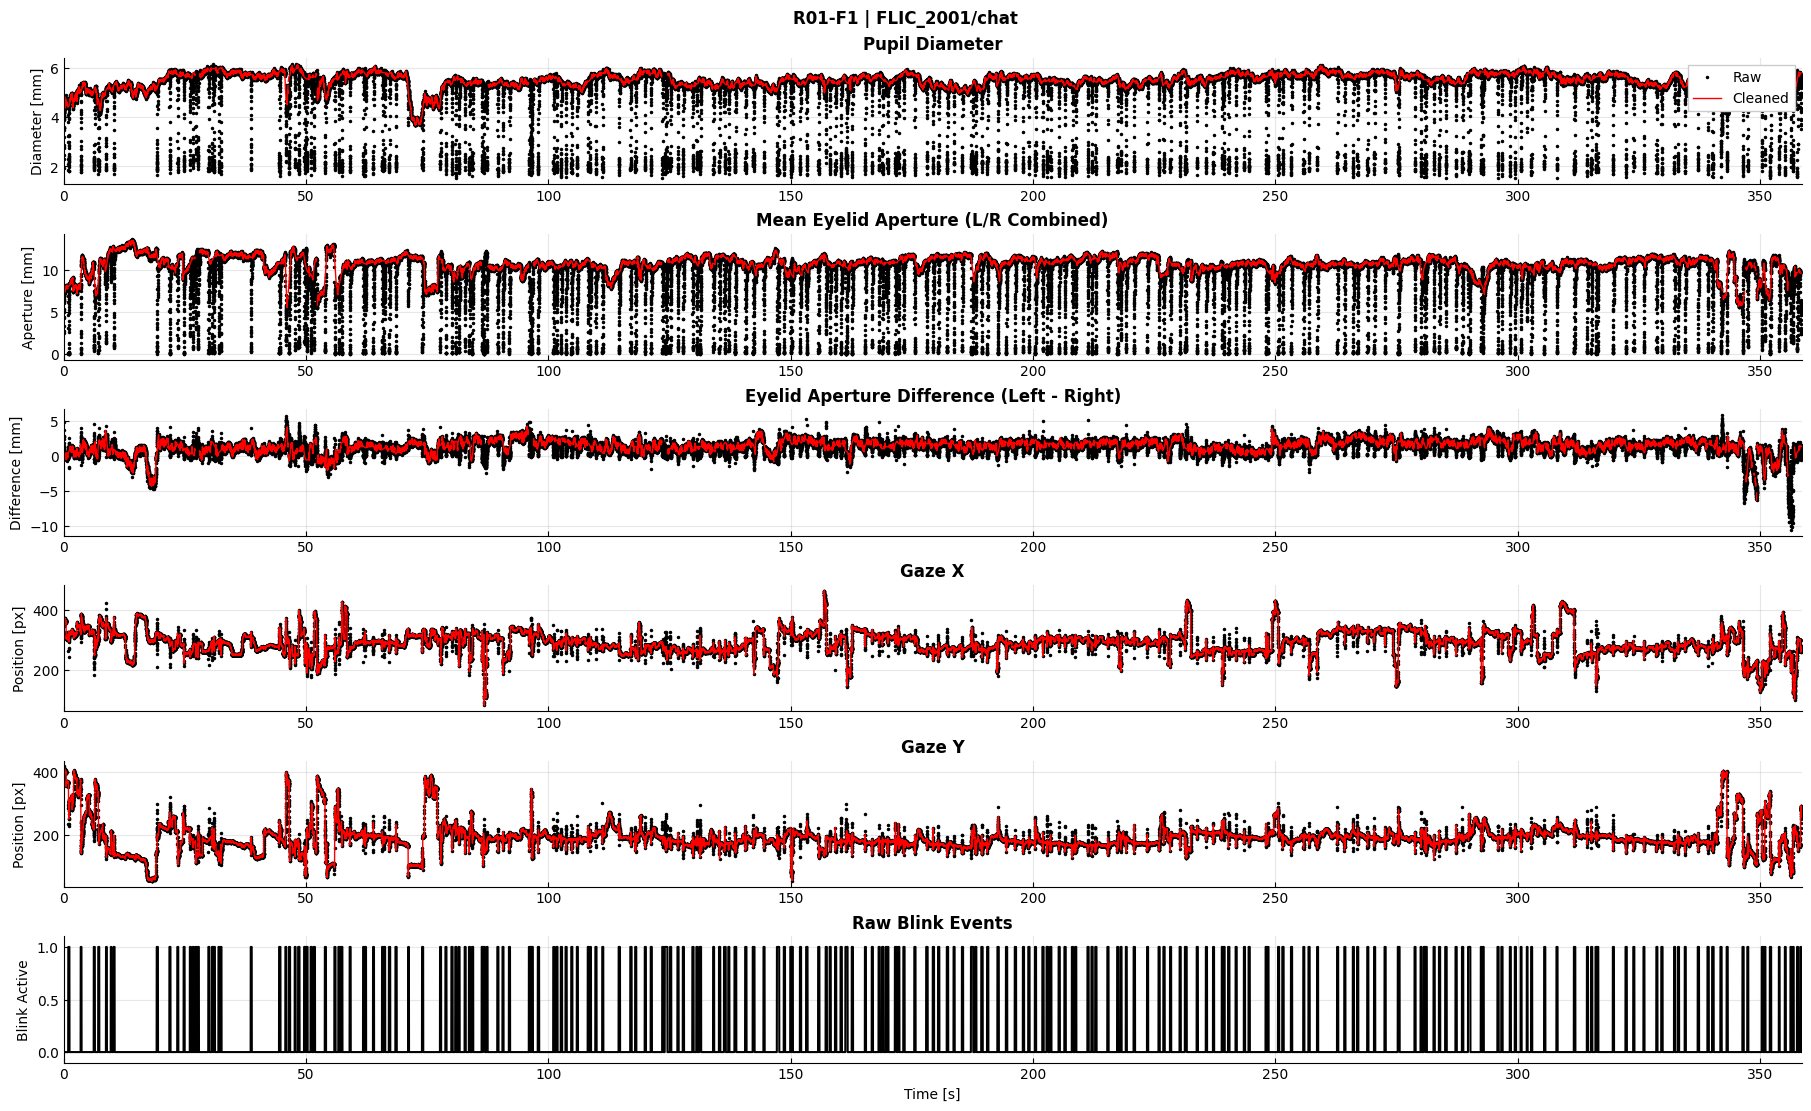

71,653 samples; 358.6 seconds


## R02 — FLIC_2001/sitBiopond

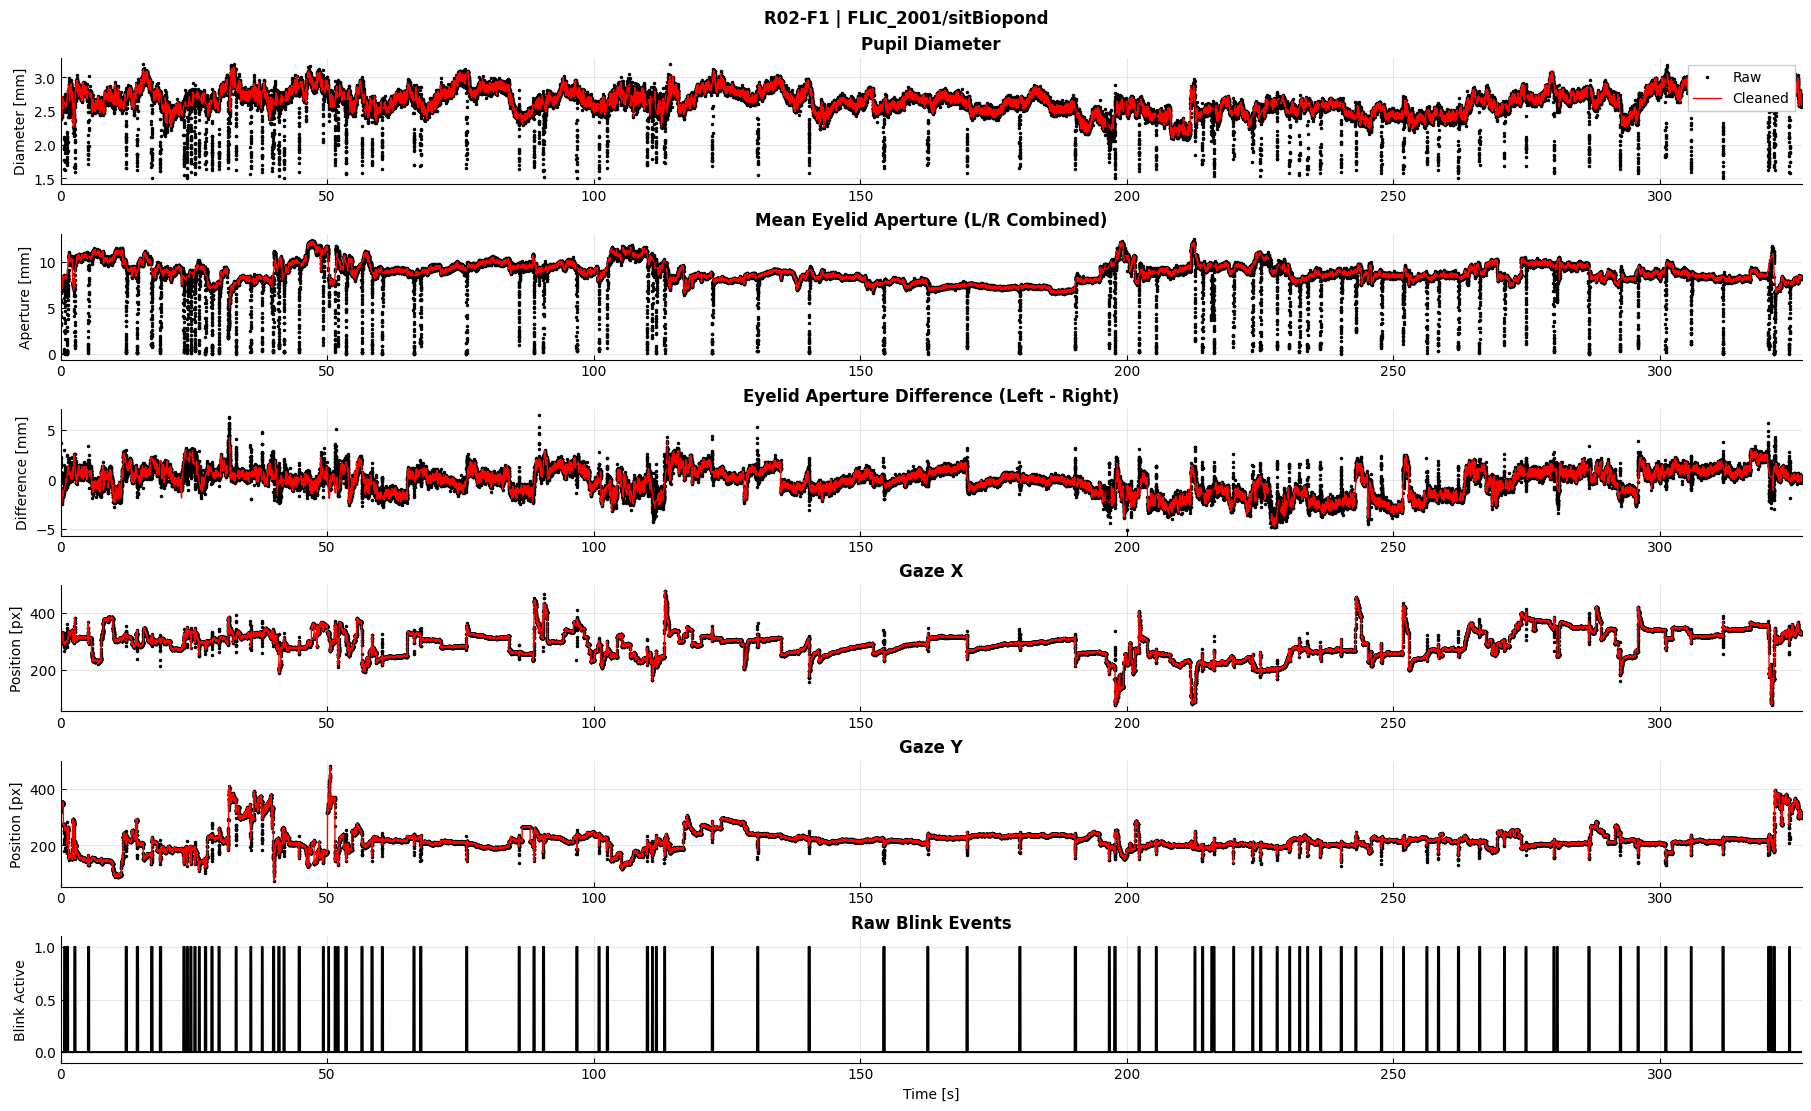

65,269 samples; 326.6 seconds


## R03 — FLIC_2001/walkBiopond

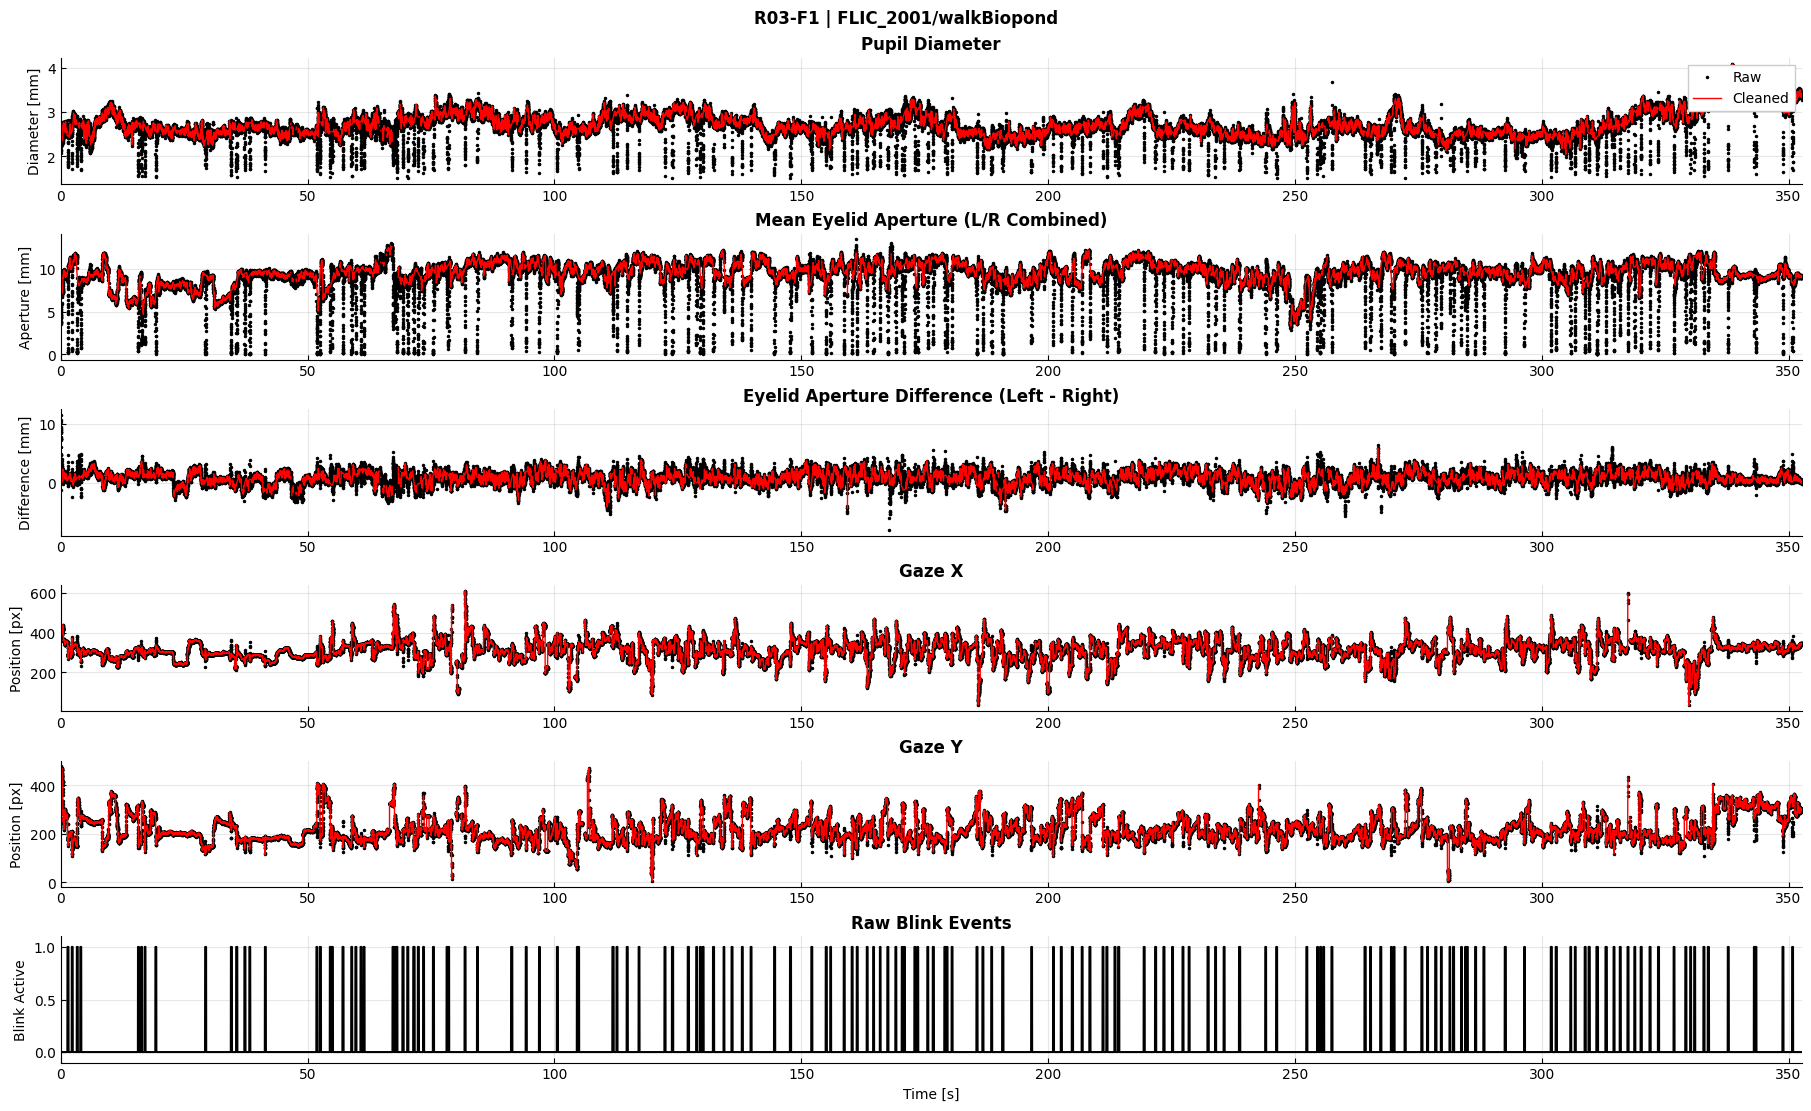

70,450 samples; 352.7 seconds


## R04 — FLIC_2001/walkIndoor

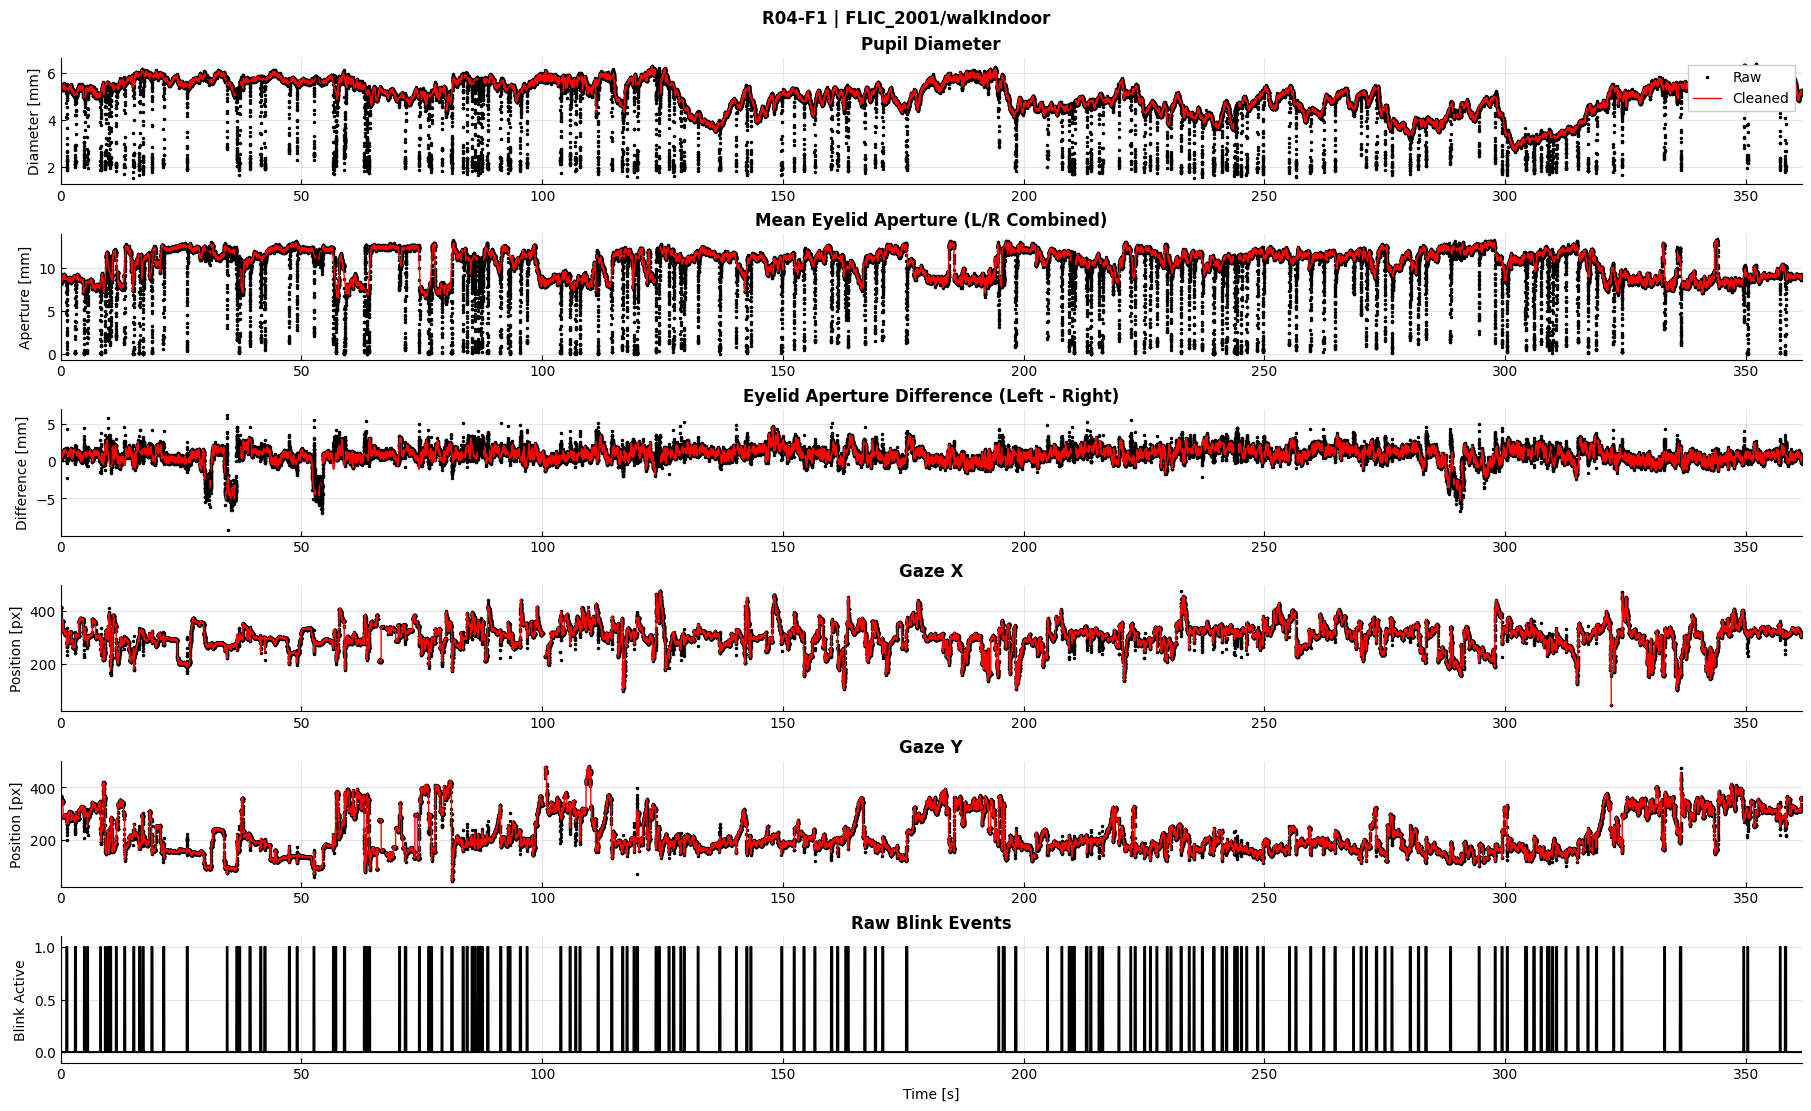

72,247 samples; 361.6 seconds


## R05 — FLIC_2001/walkOutdoor

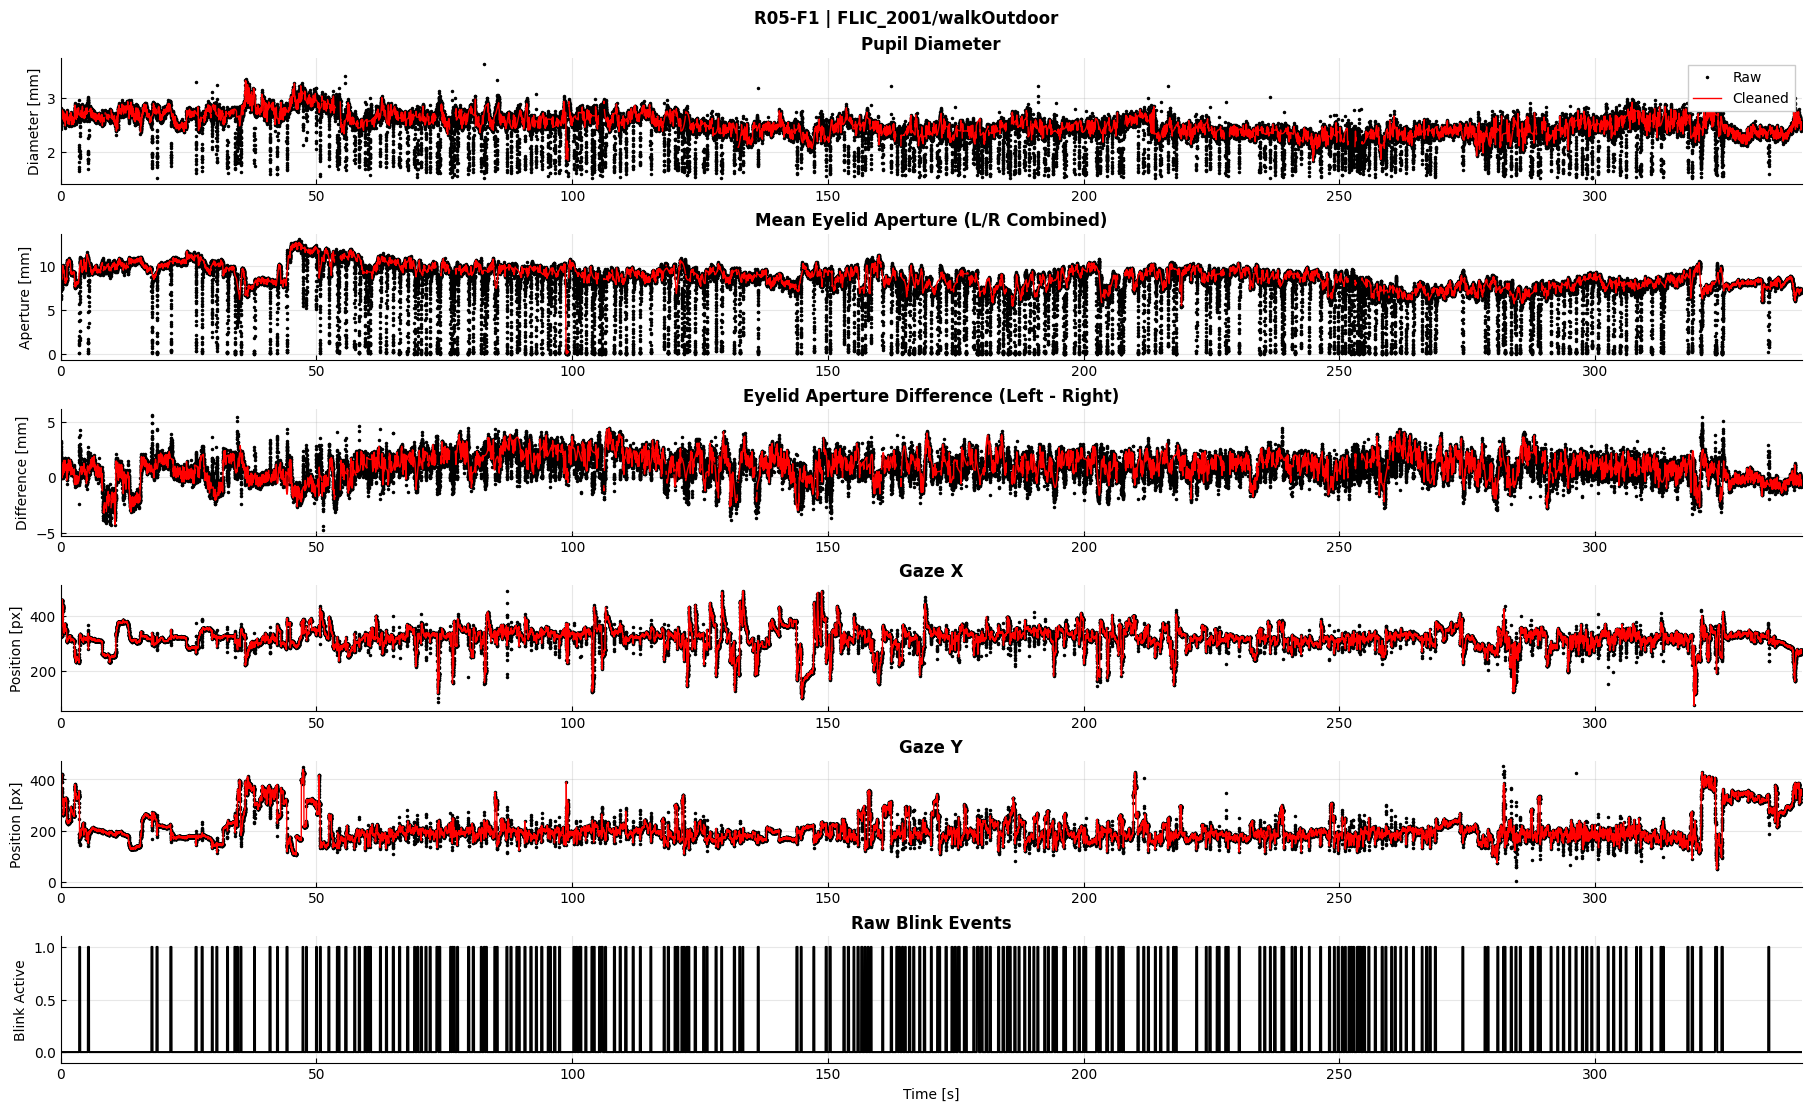

68,012 samples; 340.4 seconds


## R06 — FLIC_2002/chat

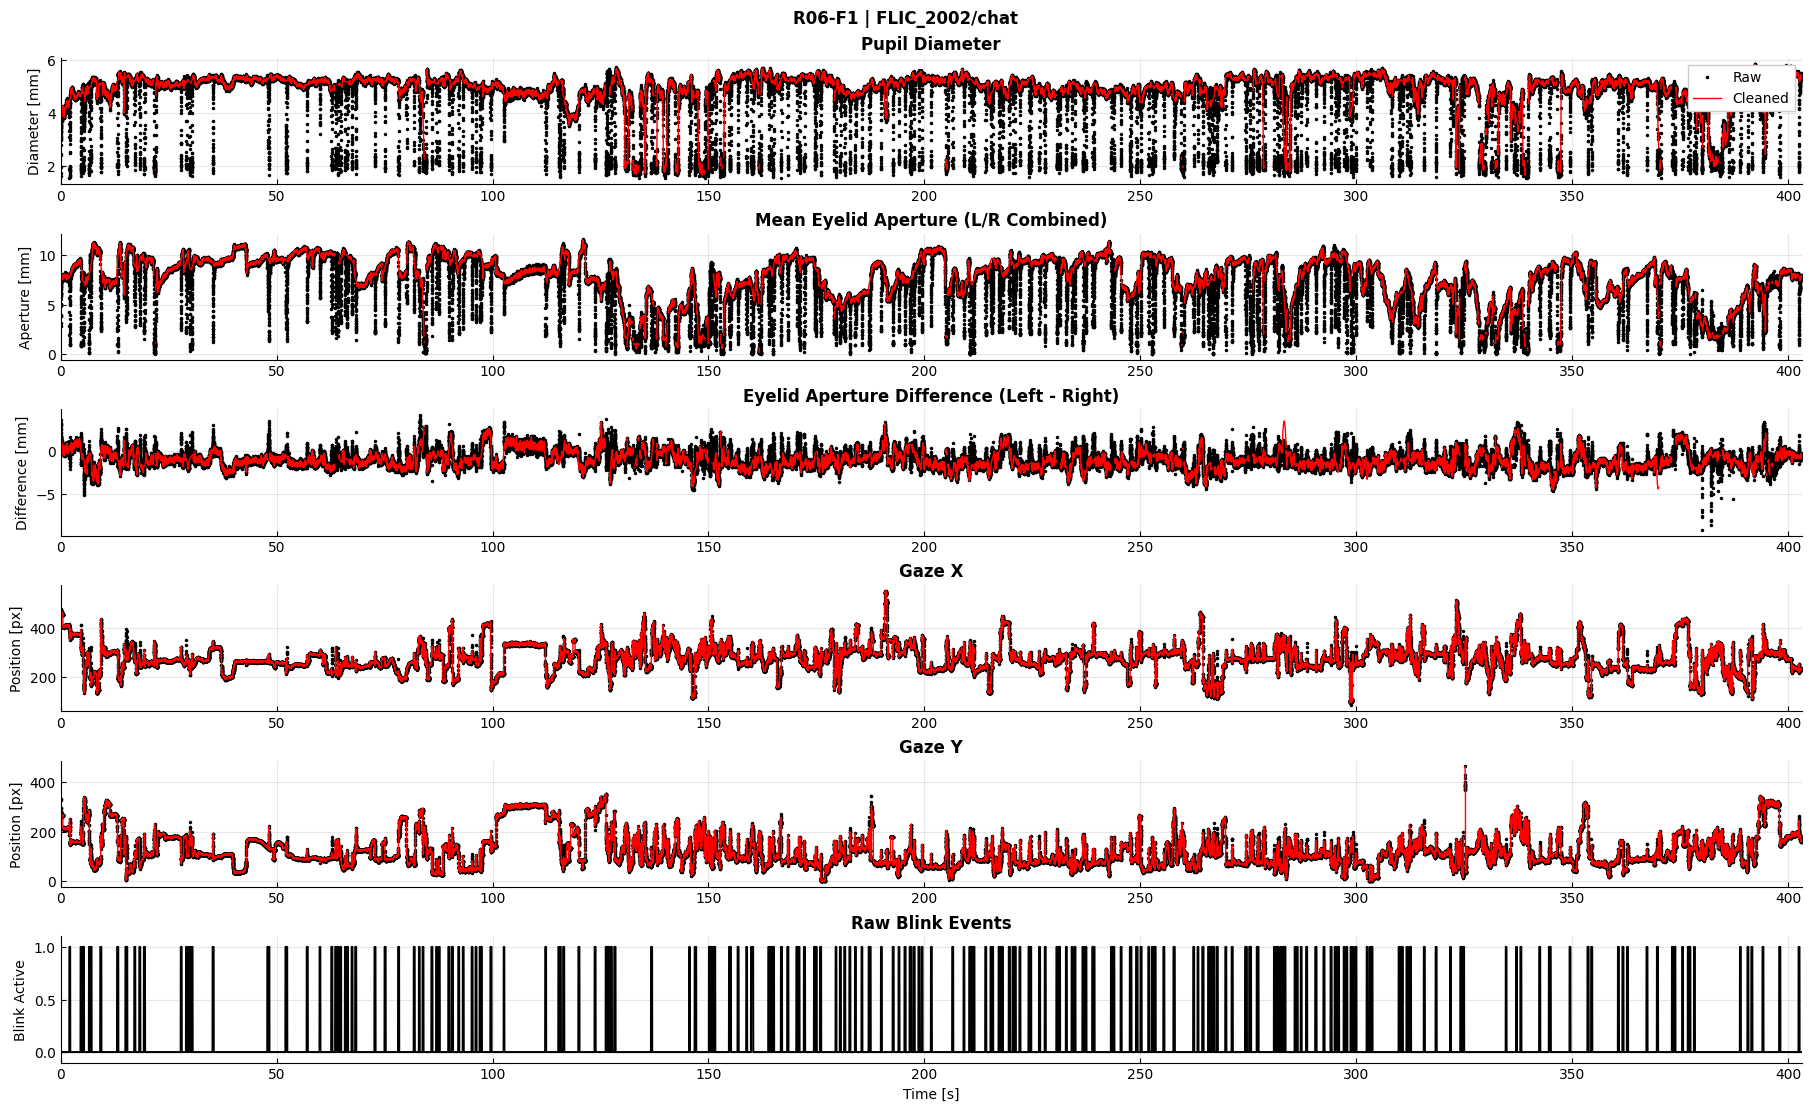

80,556 samples; 403.1 seconds


## R07 — FLIC_2002/sitBiopond

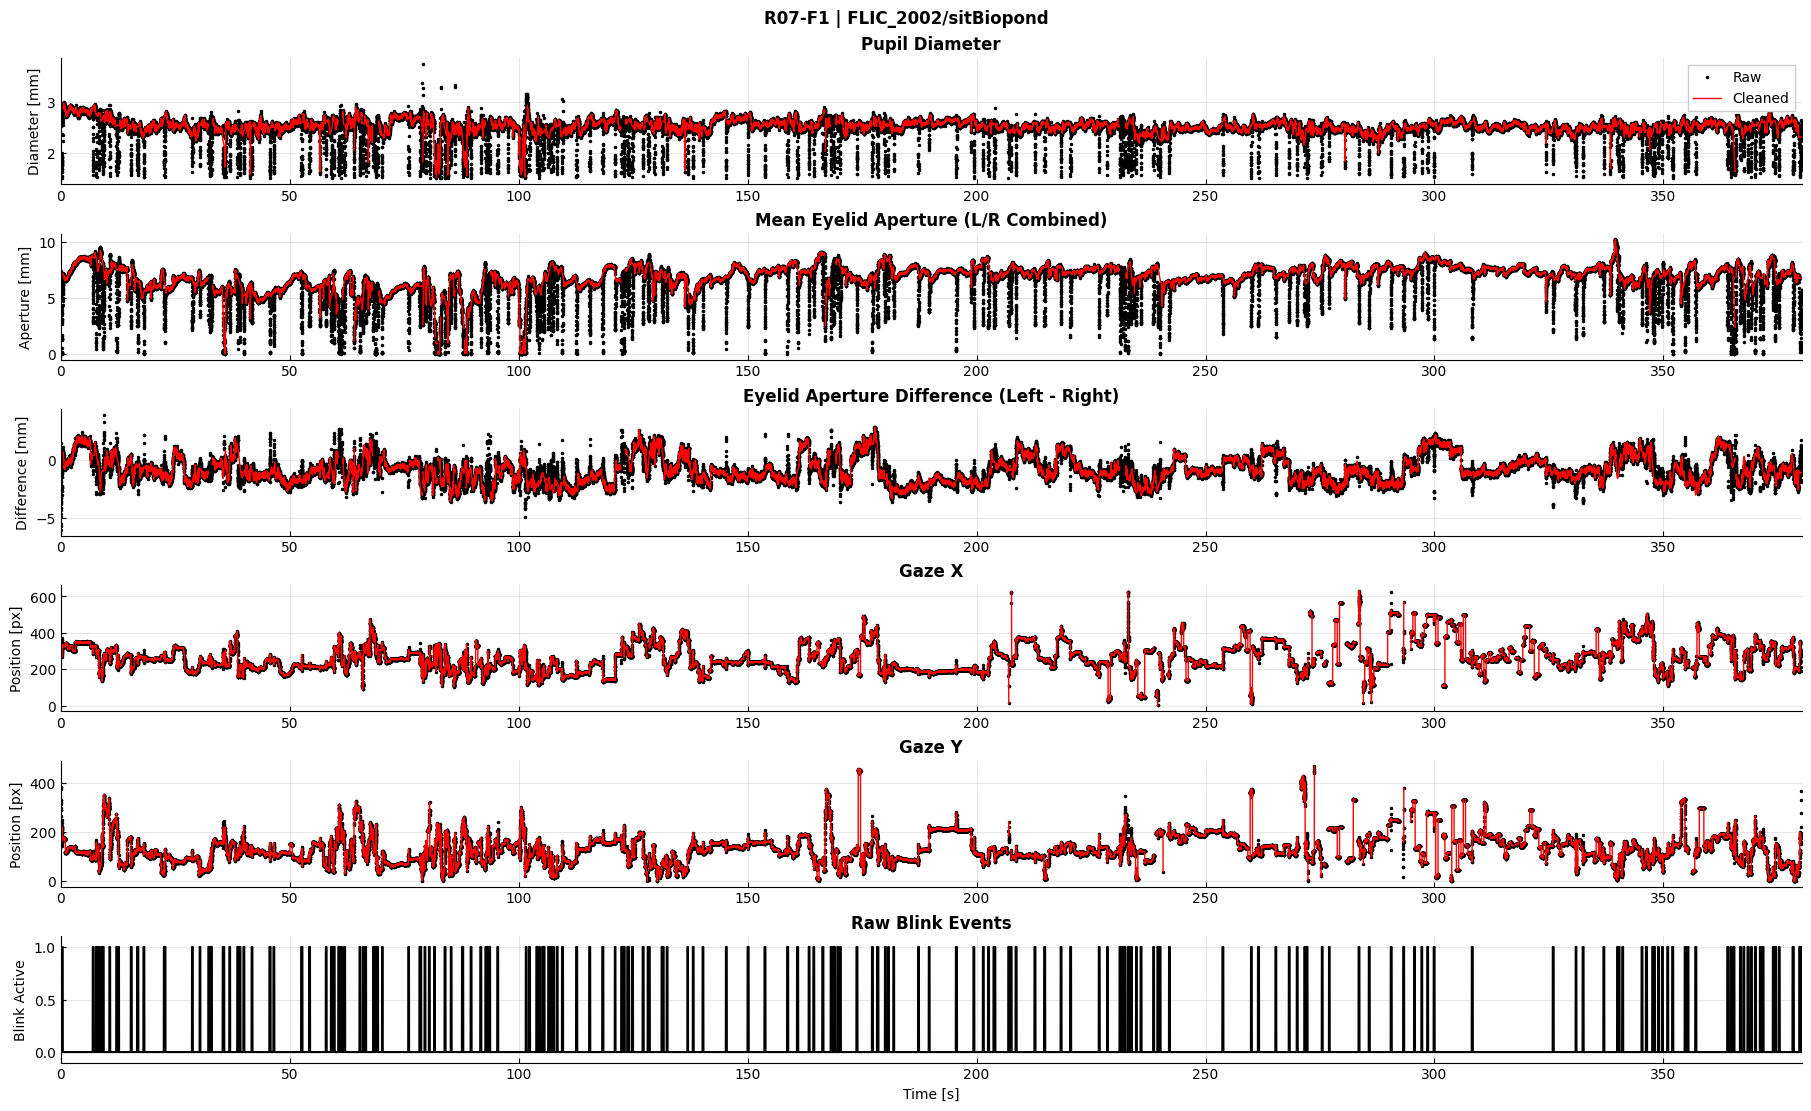

75,967 samples; 380.2 seconds


## R08 — FLIC_2002/walkBiopond

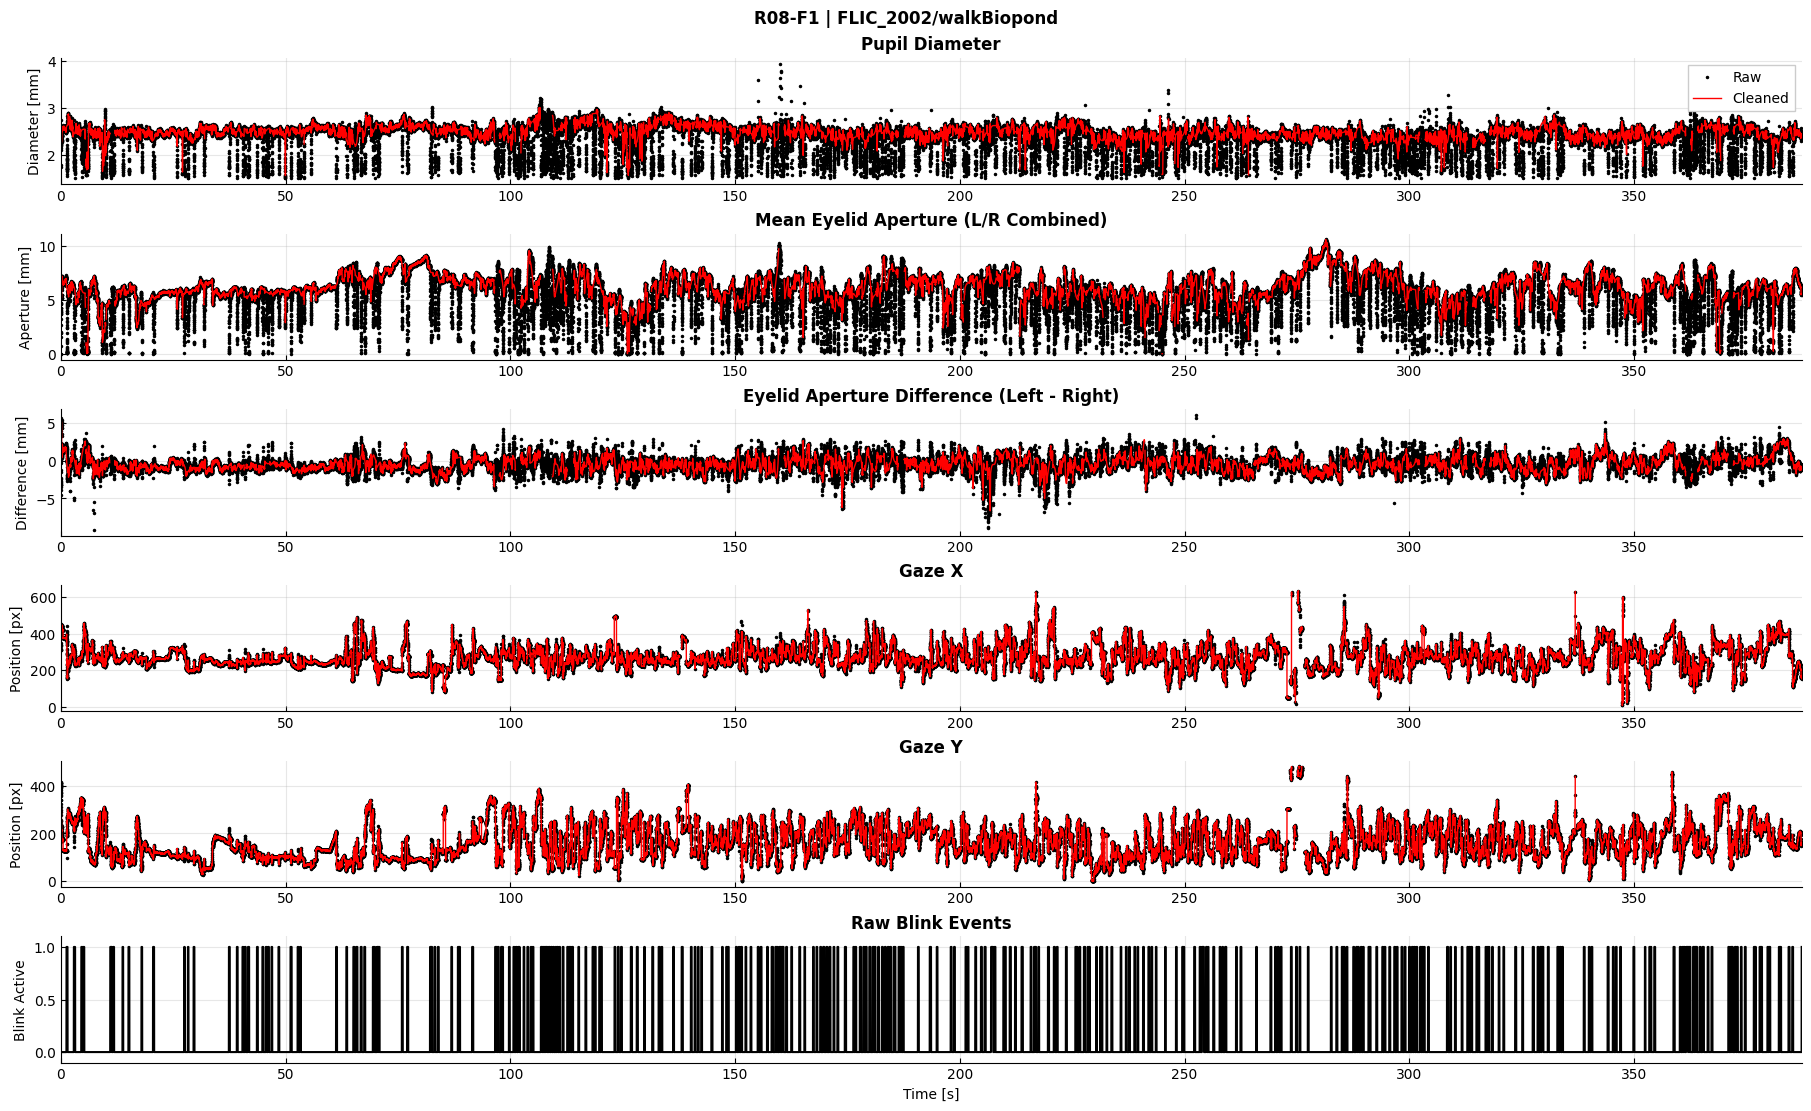

77,380 samples; 387.3 seconds


## R09 — FLIC_2002/walkIndoor

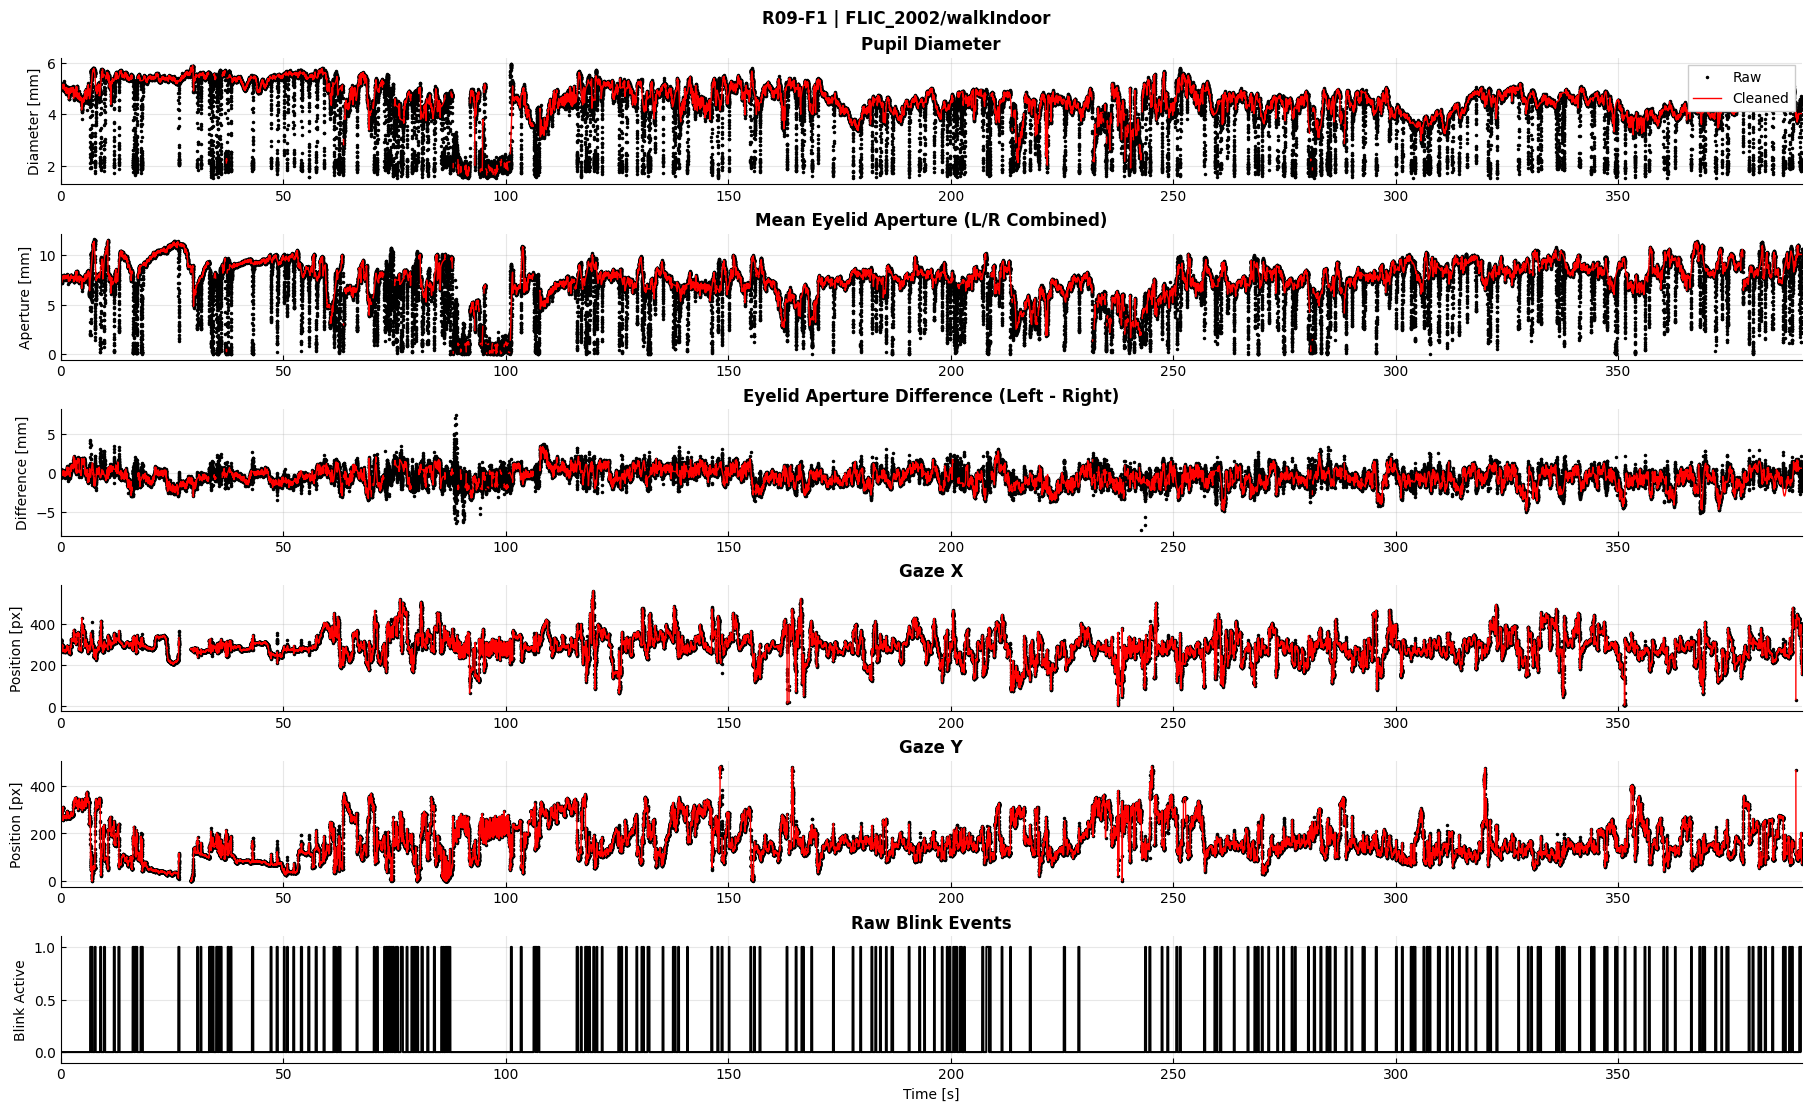

78,161 samples; 391.2 seconds


## R10 — FLIC_2002/walkOutdoor

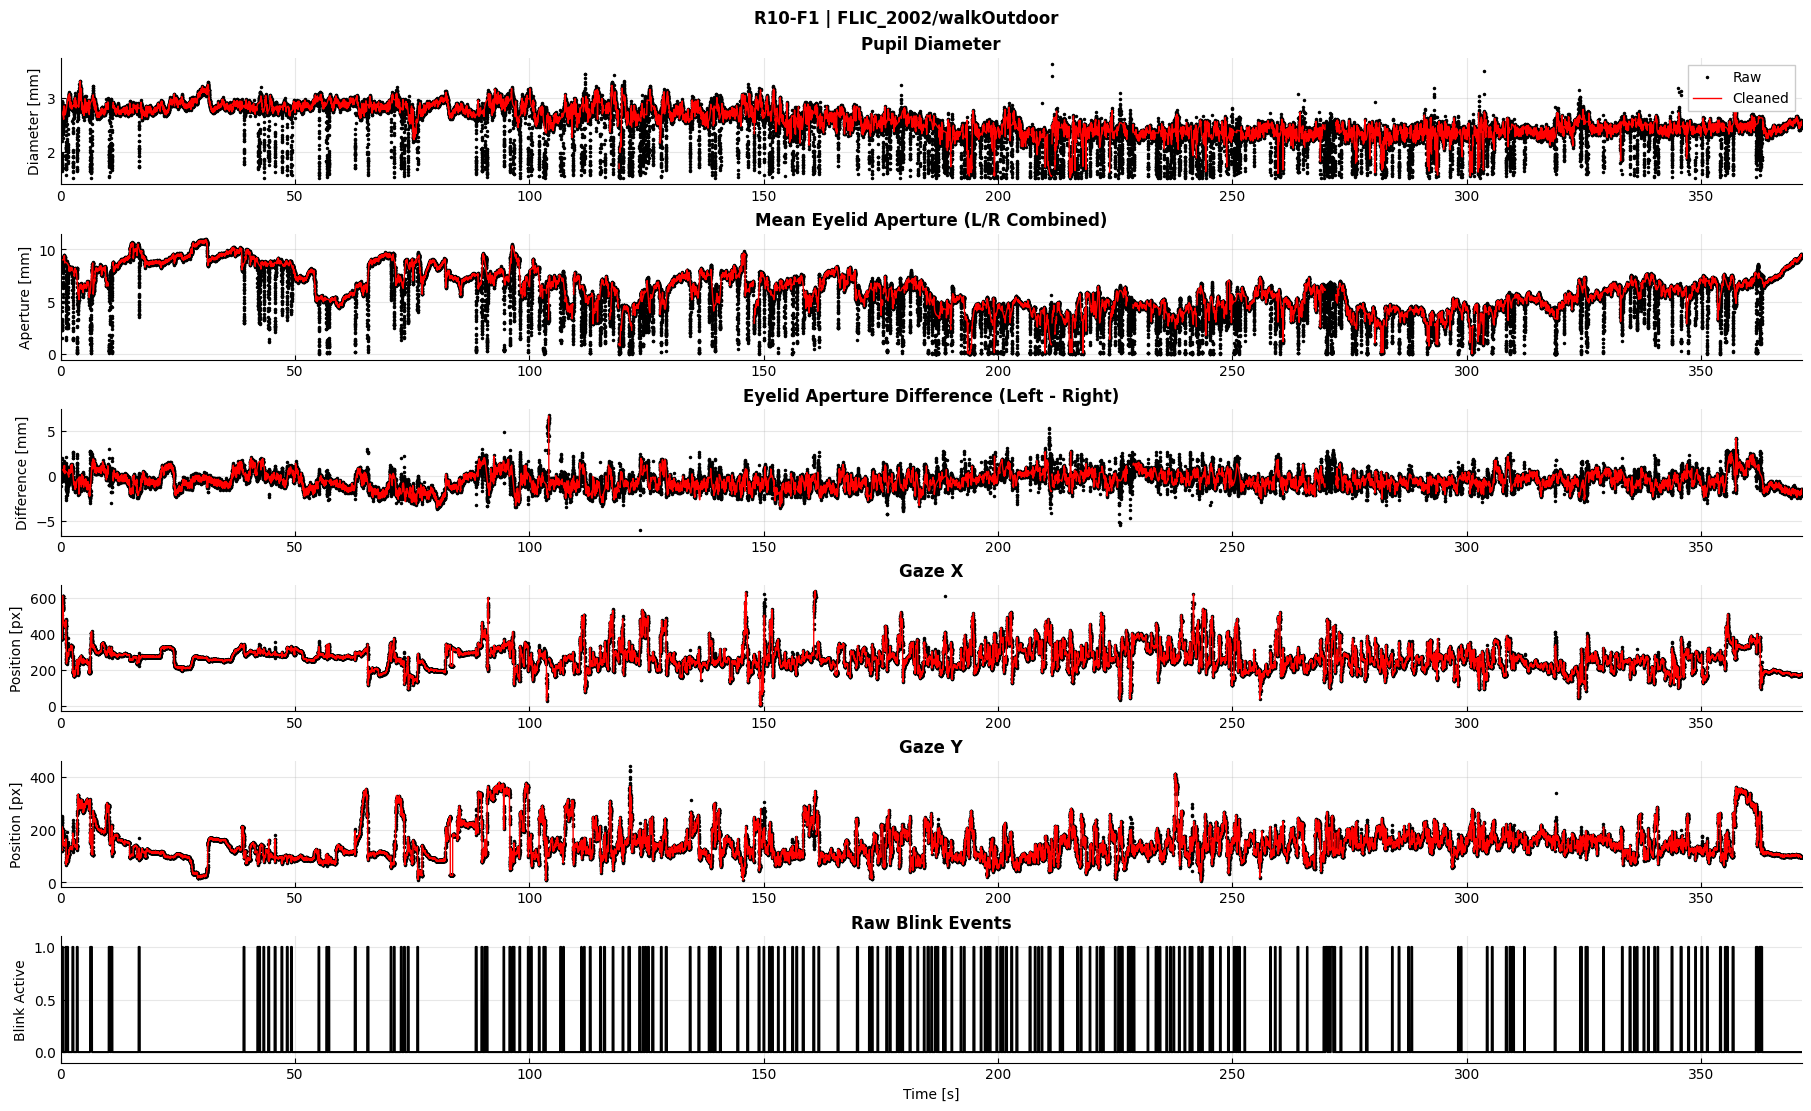

74,222 samples; 371.5 seconds


## R11 — FLIC_2003/chat

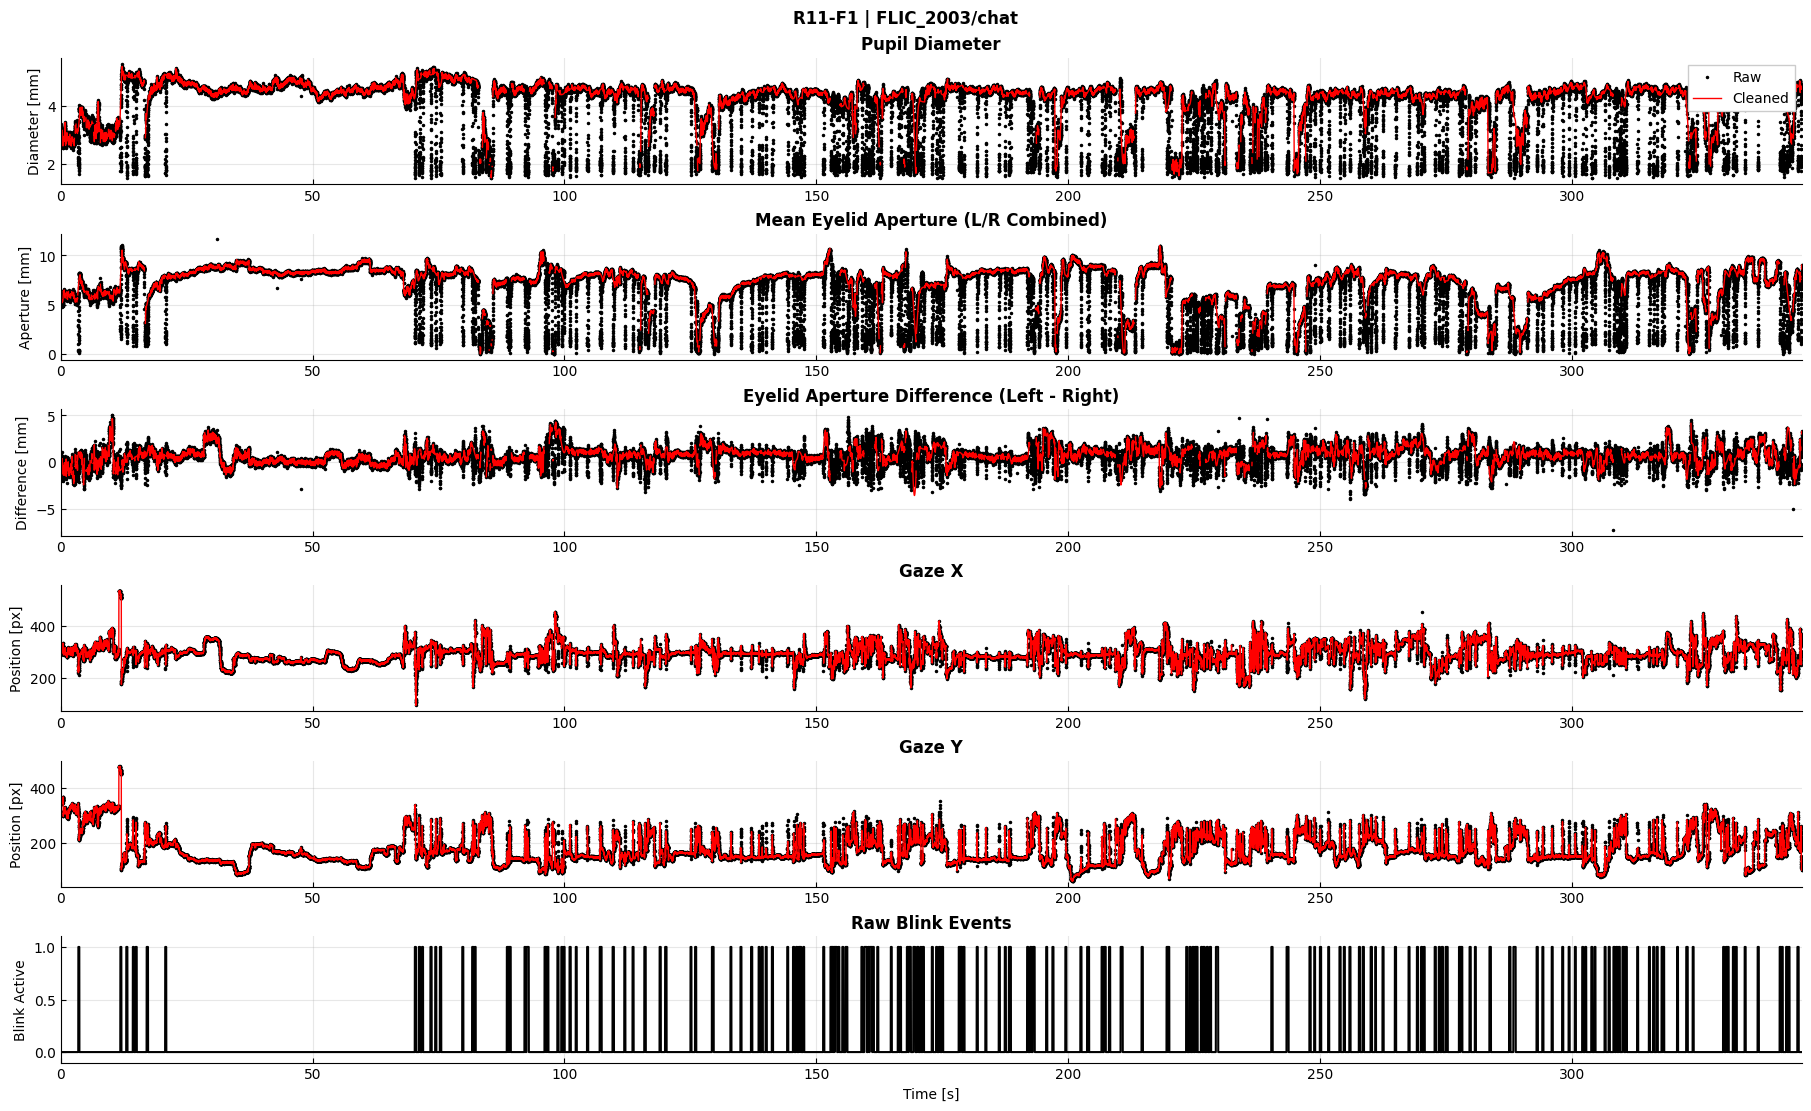

68,788 samples; 345.6 seconds


## R12 — FLIC_2003/sitBiopond

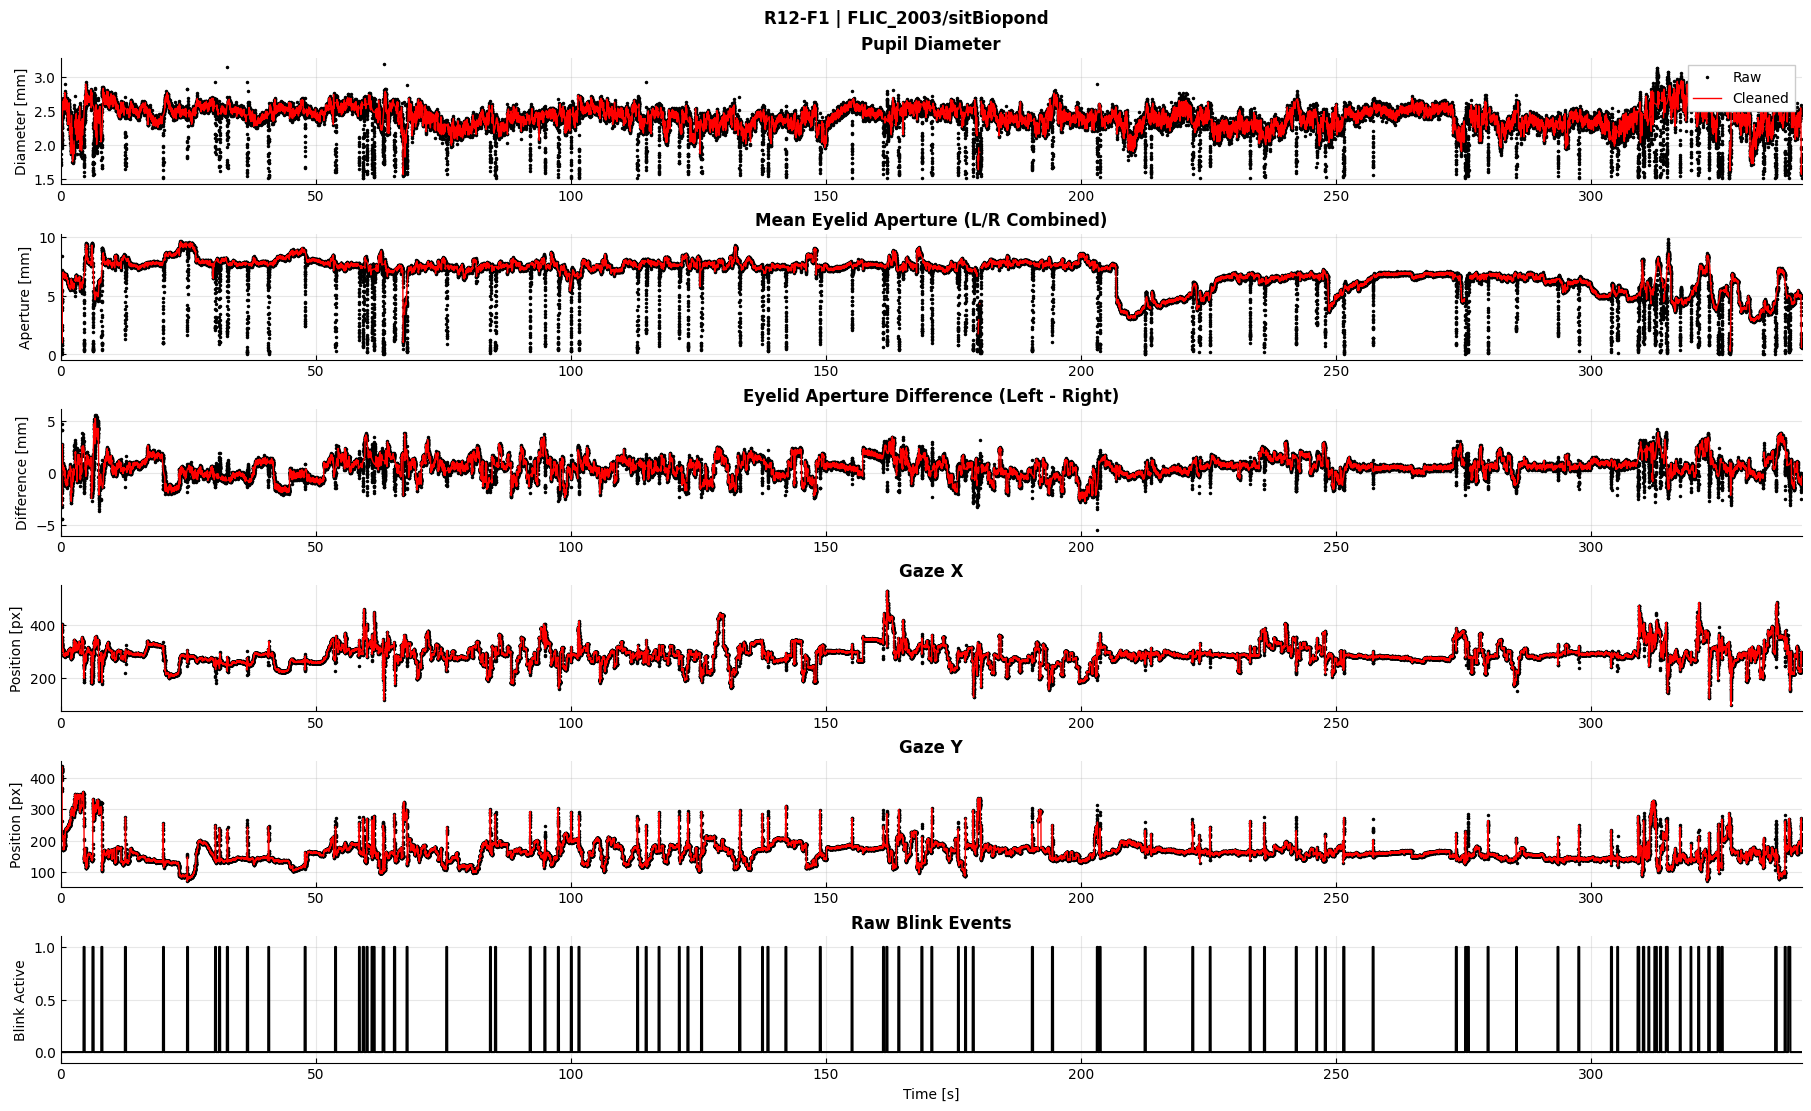

67,248 samples; 341.3 seconds


## R13 — FLIC_2003/walkBiopond

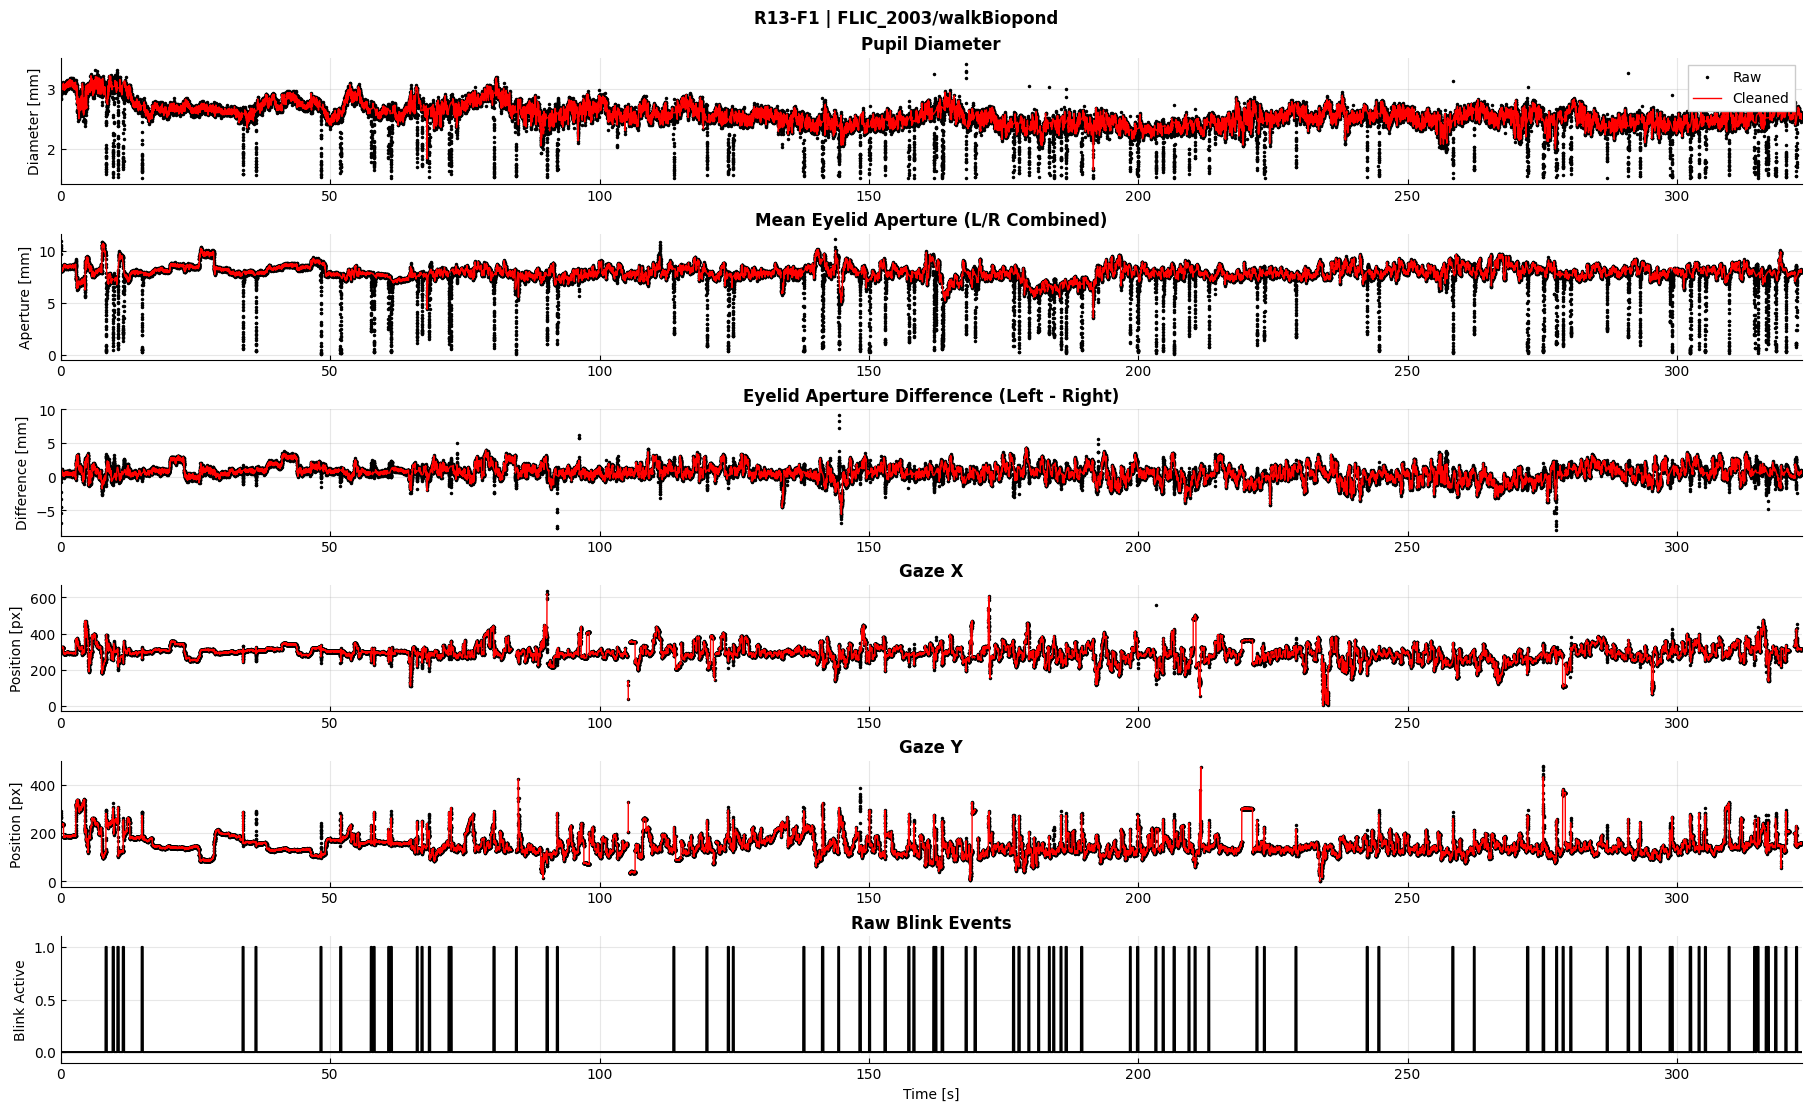

64,523 samples; 323.2 seconds


## R14 — FLIC_2003/walkIndoor

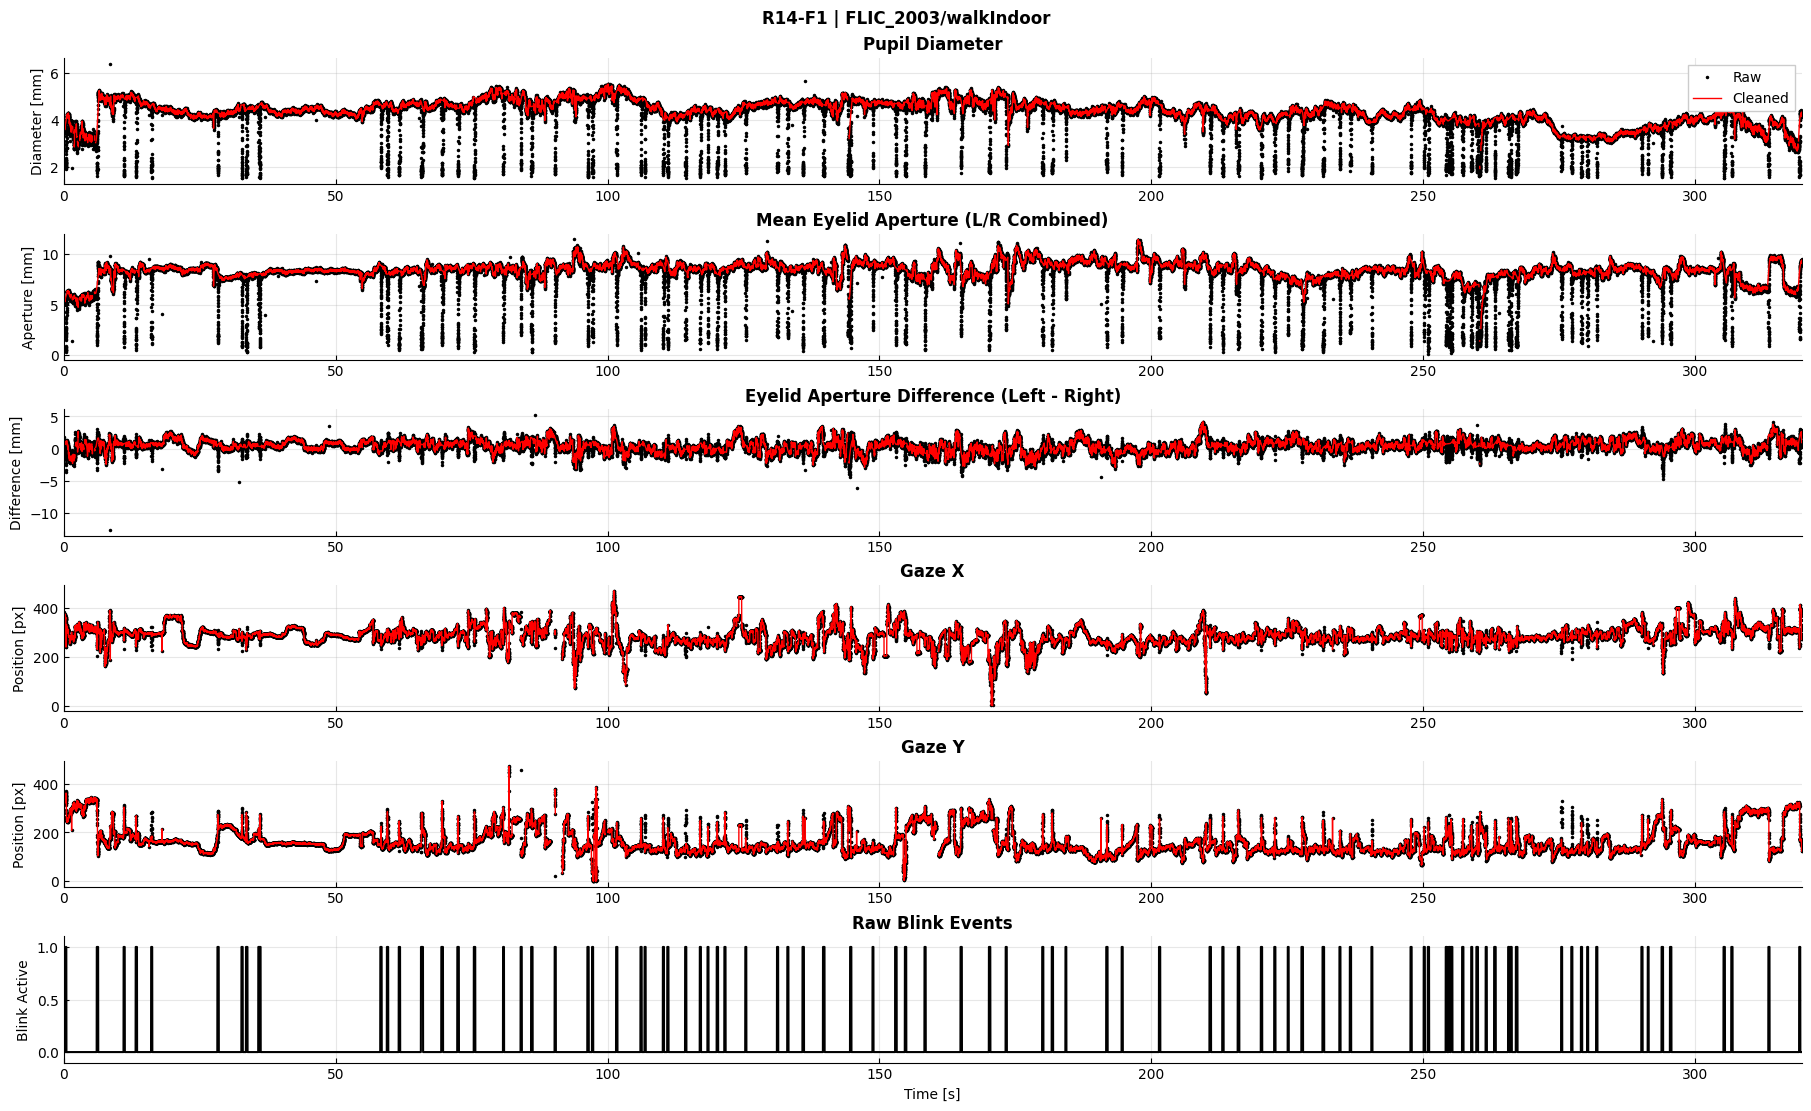

63,587 samples; 319.6 seconds


## R15 — FLIC_2003/walkOutdoor

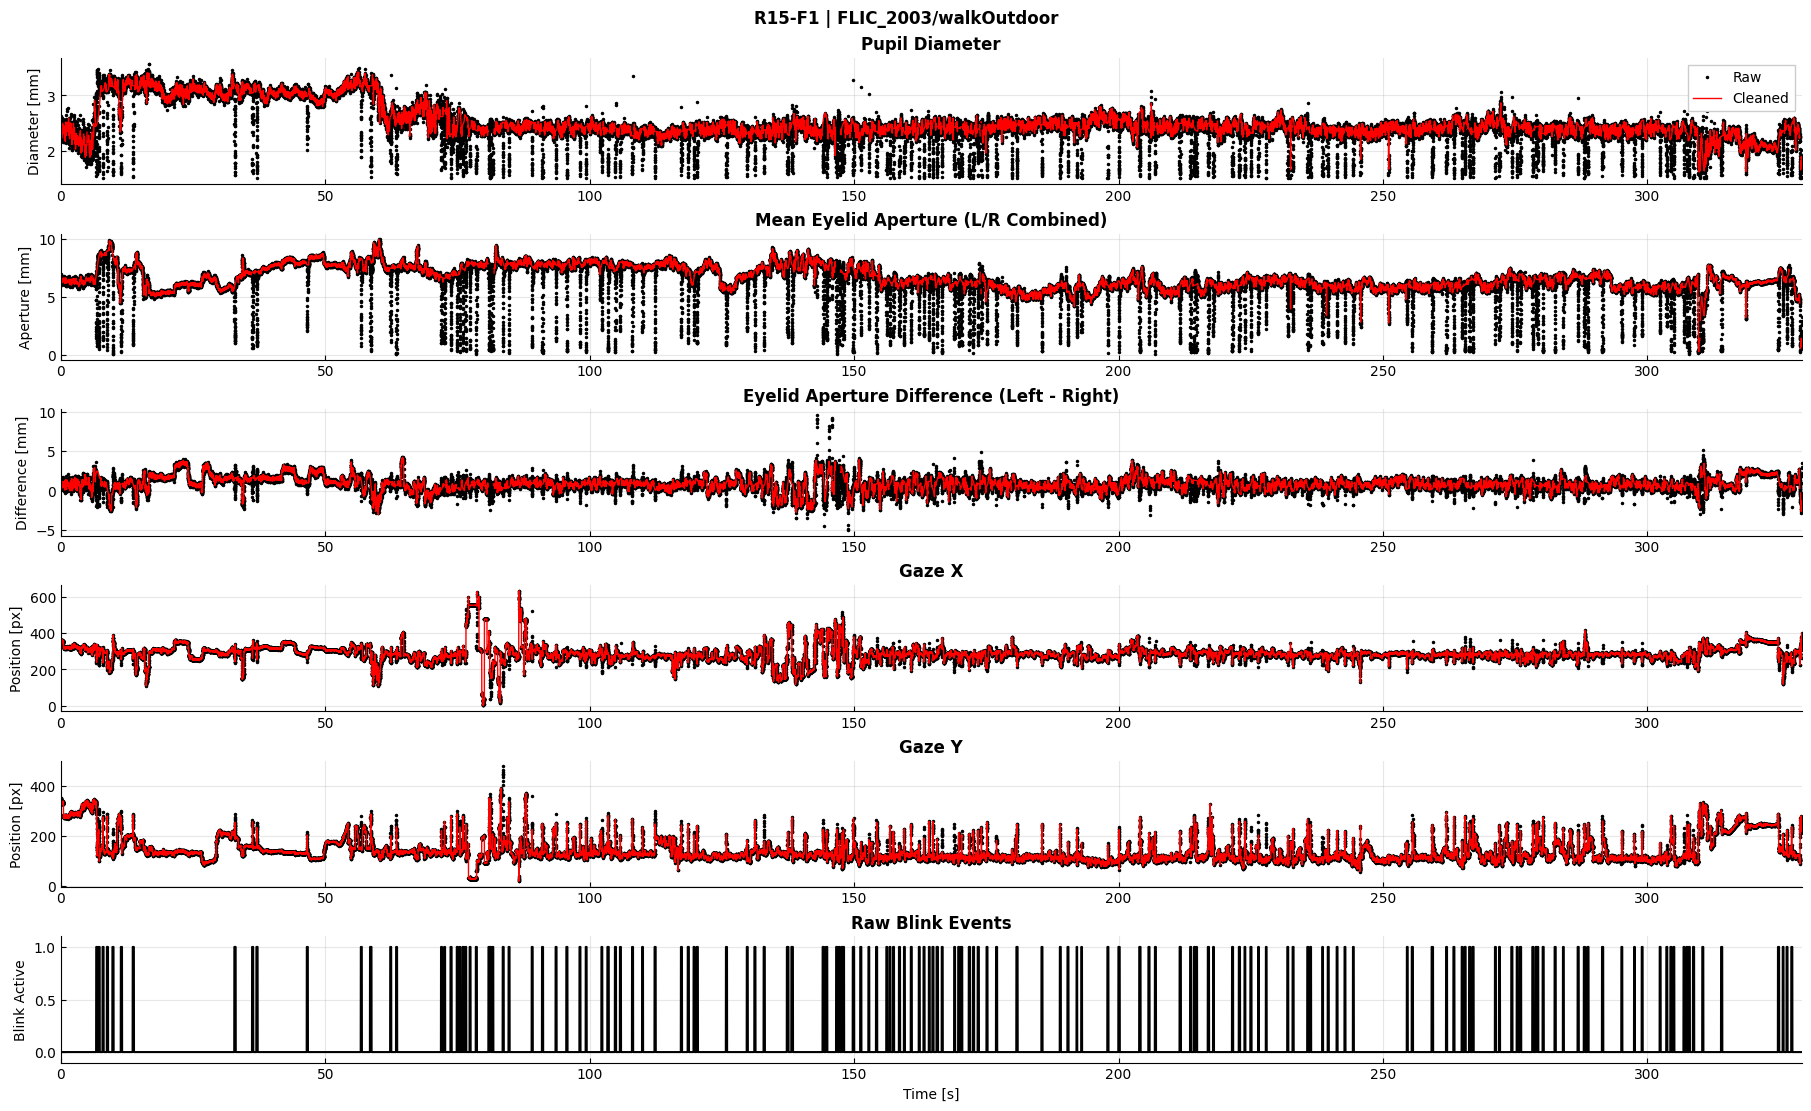

65,741 samples; 329.2 seconds
Completed 15 recording(s); 0 failed.


In [3]:
# Refresh the cleaner here too: rerunning only this cell must not reuse
# an older module/schema from before the aperture-difference column was added.
cleanEyeTracking = importlib.reload(cleanEyeTracking)
print(f"Cleaner: {cleanEyeTracking.__file__}")
print("Output columns:", ", ".join(cleanEyeTracking.OUTPUT_COLUMNS))

from contextlib import redirect_stdout
from io import StringIO

cleaned_recordings = {}
failures = {}
plot_review_rows = []

for recording_index, recording in enumerate(neon_paths, start=1):
    name = recording["recording"]
    recording_id = f"R{recording_index:02d}"
    display(Markdown(f"## {recording_id} — {name}"))
    recording_reviews = []
    existing_figures = set(plt.get_fignums())
    try:
        # Display each numbered figure exactly once, then collect its review
        # notes into a readable table instead of duplicating console messages.
        with plt.ioff(), patch.object(plt, "show"), redirect_stdout(StringIO()):
            cleaned, cleaning_metadata = cleanEyeTracking.clean_eye_data(
                str(recording["raw_neon_path"]),
                str(recording["processing_neon_path"]),
                verbose=True,
                plot_label=name,
                plot_id=recording_id,
            )
        cleaned_recordings[name] = pd.DataFrame(cleaned, columns=cleanEyeTracking.OUTPUT_COLUMNS)
        for number in sorted(set(plt.get_fignums()) - existing_figures):
            figure = plt.figure(number)
            display(figure)
            for note in figure.eye_cleaning_review:
                recording_reviews.append({
                    "Recording": name,
                    "Reference": note["reference"],
                    "Row": note["row"],
                    "Signal": ", ".join(note["signals"]),
                    "Time [s]": f"{note['start_s']:.2f}–{note['stop_s']:.2f}",
                    "Observation": note["reason"],
                    "Details": note["detail"],
                })
        if recording_reviews:
            display(Markdown("**Review candidates — inspect these; they are not confirmed fitting errors.**"))
            with pd.option_context("display.max_colwidth", None):
                display(pd.DataFrame(recording_reviews))
            plot_review_rows.extend(recording_reviews)
        print(f"{len(cleaned):,} samples; {cleaned[-1, 0]:.1f} seconds")
    except Exception as error:
        failures[name] = str(error)
        print(f"Failed: {error}")
    finally:
        for number in set(plt.get_fignums()) - existing_figures:
            plt.close(number)

print(f"Completed {len(cleaned_recordings)} recording(s); {len(failures)} failed.")

plot_review_candidates = pd.DataFrame(plot_review_rows)


## Zoomed review of flagged intervals
Run the following cell to display seven detailed raw/cleaned comparisons and save vector PDFs plus PNG previews to `output/eye_cleaning_zooms/`. This reruns cleaning using the current implementation without overwriting the batch figures or CSVs. Existing batch results remain unchanged.


In [ ]:
# Run after setup and recording discovery (cells 1–2).
# Times are seconds from the first retained gaze sample, as in the batch plots.
from unittest.mock import patch
import numpy as np

zoom_windows = [
    ("FLIC_2002/walkIndoor", 85, 102),
    ("FLIC_2002/chat", 130, 152),
    ("FLIC_2002/chat", 325, 340),
    ("FLIC_2002/sitBiopond", 270, 310),
    ("FLIC_2003/chat", 210, 240),
    ("FLIC_2003/walkOutdoor", 77, 88),
    ("FLIC_2002/walkBiopond", 274, 278),
]
# Visual review observations, not confirmed cleaning failures.
zoom_observations = {
    ("FLIC_2002/walkIndoor", 85, 102):
        "Inspect: cleaned pupil falls toward 2 mm while eyelid aperture approaches zero.\n"
        "Possible prolonged closure or tracking loss remains in the cleaned signal.",
    ("FLIC_2002/chat", 130, 152):
        "Inspect: repeated deep pupil drops coincide with very small eyelid apertures.\n"
        "Check whether closure-related measurements survive cleaning.",
    ("FLIC_2002/chat", 325, 340):
        "Inspect: repeated pupil collapses and low eyelid apertures persist after cleaning.\n"
        "Check for prolonged closure or unreliable pupil tracking.",
    ("FLIC_2002/sitBiopond", 270, 310):
        "Inspect: gaze shows large jumps, abrupt steps, and apparent discontinuities.\n"
        "Possible mapping or tracking instability; compare with the scene video.",
    ("FLIC_2003/chat", 210, 240):
        "Inspect: repeated near-zero apertures coincide with sharp cleaned-pupil drops.\n"
        "Check whether these periods should be treated as missing data.",
    ("FLIC_2003/walkOutdoor", 77, 88):
        "Inspect: large gaze excursions toward image boundaries survive cleaning.\n"
        "Compare with the scene video to distinguish real gaze shifts from tracking artifacts.",
    ("FLIC_2002/walkBiopond", 274, 278):
        "Inspect: a brief extreme gaze excursion and apparent gaps occur in both axes.\n"
        "Check for tracking loss or mapping failure around the excursion.",
}

zoom_output_dir = PROJECT_ROOT / "output" / "eye_cleaning_zooms"
zoom_output_dir.mkdir(parents=True, exist_ok=True)
recordings_by_name = {r["recording"]: r for r in neon_paths}
cleanEyeTracking = importlib.reload(cleanEyeTracking)
zoom_arrays = {}
zoom_files = []

# Capture the exact arrays used by Geoff's summary plot. This suppresses the
# full-recording figure and its PDF write without changing the cleaning logic.
def capture_summary(time, raw, cleaned, raw_blinks, *args, **kwargs):
    zoom_arrays.update(time=time, raw=raw, cleaned=cleaned, blinks=raw_blinks)

panel_titles = ["Pupil Diameter", "Mean Eyelid Aperture (L/R Combined)",
                "Eyelid Aperture Difference (Left - Right)", "Gaze X", "Gaze Y"]
panel_units = ["Diameter [mm]", "Aperture [mm]", "Difference [mm]",
               "Position [px]", "Position [px]"]

for name in dict.fromkeys(name for name, _, _ in zoom_windows):
    if name not in recordings_by_name:
        print(f"Skipped {name}: not present in neon_paths; include it in the filters above.")
        continue
    recording = recordings_by_name[name]
    zoom_arrays.clear()
    with patch.object(cleanEyeTracking, "_plot_matlab_summary", side_effect=capture_summary):
        cleanEyeTracking.clean_eye_data(
            str(recording["raw_neon_path"]),
            str(recording["processing_neon_path"]), verbose=True,
        )
    t = zoom_arrays["time"]
    for window_name, start, stop in zoom_windows:
        if window_name != name:
            continue
        keep = (t >= start) & (t <= stop)
        if not np.any(keep):
            print(f"Skipped {name}, {start}–{stop} s: no samples.")
            continue
        with plt.ioff():
            fig, axes = plt.subplots(6, 1, figsize=(16, 11), sharex=True,
                                     constrained_layout=True)
            observation = zoom_observations.get(
                (name, start, stop), "Inspect: additional review window.")
            fig.suptitle(
                f"{name} | {start}–{stop} s | Raw vs Cleaned\n{observation}",
                fontsize=12, fontweight="bold", linespacing=1.5,
            )
            for col, ax in enumerate(axes[:5]):
                ax.plot(t[keep], zoom_arrays["raw"][keep, col], "k.",
                        markersize=2.5, label="Raw")
                ax.plot(t[keep], zoom_arrays["cleaned"][keep, col], "r-",
                        linewidth=1, label="Cleaned")
                ax.set_title(panel_titles[col], fontweight="bold")
                ax.set_ylabel(panel_units[col])
            axes[0].legend(loc="upper right")
            axes[5].step(t[keep], zoom_arrays["blinks"][keep].astype(float),
                         where="post", color="black", linewidth=1)
            axes[5].set(title="Raw Blink Events", ylabel="Blink Active", ylim=(-0.1, 1.1))
            axes[5].set_xlabel("Time from first retained gaze sample [s]")
            for ax in axes:
                ax.set_xlim(start, stop)
                ax.grid(alpha=0.3)
                ax.tick_params(axis="x", labelbottom=True)
                ax.spines[["top", "right"]].set_visible(False)
            stem = f"{name.replace('/', '_')}_{start}-{stop}s"
            pdf_path = zoom_output_dir / f"{stem}.pdf"
            fig.savefig(pdf_path, format="pdf")
            fig.savefig(zoom_output_dir / f"{stem}.png", dpi=160)
            zoom_files.append(pdf_path)
            display(fig)
            plt.close(fig)
print(f"Saved {len(zoom_files)} zoom plots to {zoom_output_dir}")


## Does our filtering create the gaze gaps?
Compare the original mapped CSV to bounds filtering, blink/spike masking, filling, and smoothing. The bounds filter removes **both coordinates** whenever either is outside its limits. If a gap first appears in row 2, our bounds filter caused it; if it already appears in row 1, it precedes eye cleaning. Bounds removal does not by itself establish a mapping error: verify the mapped coordinate system and target image dimensions.


In [ ]:
# Audit the actual cleaner; no alternative implementation or changed thresholds.
import numpy as np
cleanEyeTracking = importlib.reload(cleanEyeTracking)
audit_name = "FLIC_2002/walkBiopond"
audit_start, audit_stop = 274, 278
recording = next(r for r in neon_paths if r["recording"] == audit_name)
audit = {}
_ = cleanEyeTracking.clean_eye_data(
    str(recording["raw_neon_path"]), str(recording["processing_neon_path"]),
    verbose=False, diagnostics=audit,
)
t = audit["time"]
keep = (t >= audit_start) & (t <= audit_stop)
if not keep.any():
    raise ValueError("No samples in the requested diagnostic window.")
steps = [("Mapped CSV (before our filters)", "mapped_gaze"),
         ("After bounds filter", "bounded_gaze"),
         ("After blink AND spike mask", "masked_gaze"),
         ("After nearest gap filling", "filled_gaze"),
         ("After smoothing (final)", "cleaned_gaze")]
with plt.ioff():
    fig, axes = plt.subplots(6, 2, figsize=(17, 15), sharex=True,
                             constrained_layout=True)
    fig.suptitle(f"{audit_name} | {audit_start}–{audit_stop} s | Filtering audit\n"
                 "First row is original mapped CSV data; subsequent rows expose our filtering.",
                 fontsize=13, fontweight="bold")
    for row, (label, key) in enumerate(steps):
        for col, limit in enumerate((cleanEyeTracking.GAZE_FRAME_WIDTH,
                                     cleanEyeTracking.GAZE_FRAME_HEIGHT)):
            ax = axes[row, col]
            ax.plot(t[keep], audit[key][keep, col], ".-", markersize=2, linewidth=.6)
            ax.axhline(0, color="gray", linestyle="--", linewidth=.7)
            ax.axhline(limit, color="gray", linestyle="--", linewidth=.7)
            ax.set_title(f"{label} — Gaze {'XY'[col]}")
            ax.set_ylabel("Position [px]")
    for col in range(2):
        ax = axes[5, col]
        masks = [("Input nonfinite", ~np.isfinite(audit["mapped_gaze"][:, col])),
                 ("Either axis out of bounds", audit["out_of_bounds"]),
                 ("Blink AND spike", audit["gaze_mask"]),
                 ("Final nonfinite", ~np.isfinite(audit["cleaned_gaze"][:, col]))]
        for row, (label, mask) in enumerate(masks):
            ax.step(t[keep], row + .7 * mask[keep], where="post", label=label)
        ax.set_yticks(np.arange(4), [label for label, _ in masks])
        ax.set_title("Where samples are rejected or missing")
        ax.set_xlabel("Time [s]")
    for ax in axes.flat:
        ax.set_xlim(audit_start, audit_stop)
        ax.grid(alpha=.25)
    audit_dir = PROJECT_ROOT / "output" / "eye_cleaning_zooms"
    audit_dir.mkdir(parents=True, exist_ok=True)
    audit_pdf = audit_dir / "FLIC_2002_walkBiopond_274-278s_filtering_audit.pdf"
    fig.savefig(audit_pdf)
    display(fig)
    plt.close(fig)

# Counts are samples within this window, not durations; masks can overlap.
counts = []
for label, key in steps:
    values = audit[key][keep]
    counts.append({"Step": label, "X nonfinite": (~np.isfinite(values[:, 0])).sum(),
                   "Y nonfinite": (~np.isfinite(values[:, 1])).sum()})
display(pd.DataFrame(counts))
print(f"Samples in window: {keep.sum()}; rejected by bounds: {audit['out_of_bounds'][keep].sum()}; "
      f"blink AND spike mask: {audit['gaze_mask'][keep].sum()}")
print(f"Largest timestamp spacing in window: {np.diff(t[keep]).max():.4f} s")
print(f"Saved {audit_pdf}")
